# ViGoEmotions: midterm notebook (Parts A, B, C, D)

**Task:** fine-grained multi-label emotion recognition on Vietnamese social-media comments
(ViGoEmotions, EACL 2026): 20,664 comments, 27 emotions + `neutral` = **28 labels**, all 28 used for training and reporting.

| Brief section | What this notebook does | Notebook section |
|---|---|---|
| A. Dataset analysis | inventory, frequency + head/mid/tail, cardinality, co-occurrence, length, informal-text review, split protocol | 2 |
| Preprocessing | normalisation, emoji → text, word segmentation, length budgets | 3 |
| B. Required models | TF-IDF + One-vs-Rest Logistic Regression · BiLSTM · PhoBERT (sigmoid head + BCE) | 4 |
| C. Required metrics | Macro/Micro-F1, per-label F1, Hamming loss, LRAP, mAP, parameter count, training time | 5 |
| D. Midterm questions | Q1–Q5, each answered by code | 6 |
| Error analysis | cardinality breakdown, FN/FP per label, confused pairs, edge cases, confusion matrices | 7 |
| Report | auto-generated summary + proposed Final research question | 8 |

**Paths.** All paths are relative to the project root, the folder that holds `notebooks/` and `splits/` (the
repository root on GitHub, `code/` in the course submission). The setup cell finds it on its own: locally, start
Jupyter in that folder or in `notebooks/`; on Colab, either clone the repository and `%cd` into it, or upload the
folder to *My Drive* and open the notebook from there (the cell mounts Drive and looks for
`62FIT4ATI-CLC02_G02_P02/code`). If `data/` is empty, the dataset is downloaded from the authors' GitHub repository
and checked against `splits/`.

**How to run (Colab):** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**.
1. The dataset files (`train.csv`, `val.csv`, `test.csv`, `label_dict.json`) are read from `data/`.
2. Trained models and their saved probabilities are written to `runs/<model>/` (model weights are neither submitted nor pushed to GitHub).
   On a later run they are **loaded instead of retrained** (unless `RETRAIN = True` or the configuration changed),
   so a Colab disconnect does not lose finished work.
3. Split index files (comment ids only) and SHA-256 checksums of the CSVs are written to `splits/`;
   per-comment predictions and result tables are written to `results/` (Section 5.1).
4. Every table and figure is printed / drawn inside this notebook.

**Experimental rules**
- The official split is used unchanged. Hyper-parameters and epochs are selected on **validation** Macro-F1 at τ = 0.5;
  the test set is evaluated once with the selected model, never used for selection.
- Statistics that drive a decision (tiers, length budgets, slice cut-offs) come from **train** only.
- **License:** the dataset must not be redistributed. Cells that show examples print comment **ids** instead of text
  unless `SHOW_COMMENT_TEXT = True` (Section 1); keep it `False` in any shared copy. Saved files contain no comment text.

## 1. Setup

In [1]:
!pip install -q underthesea==9.5.0 emoji==2.16.0

In [2]:
import urllib.request
from pathlib import Path

PREFIX = '62FIT4ATI-CLC02_G02_P02'
DATA_URL = 'https://raw.githubusercontent.com/ricardo-tran/ViGoEmotions/main/corpus/'   # official dataset repo
DATA_FILES = ['train.csv', 'val.csv', 'test.csv', 'label_dict.json']


def find_code_dir():
    """Project root: the folder holding notebooks/ and splits/ (repository root, or code/ in the submission)."""
    here = Path.cwd().resolve()
    for p in (here, here.parent):                     # local Jupyter started in notebooks/ or the project root
        if (p / 'notebooks').is_dir() and (p / 'splits').is_dir():
            return p
    try:                                              # Colab: the notebook was opened from Google Drive
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Start Jupyter in the project root (the folder with notebooks/ and splits/) or in notebooks/.')
    drive.mount('/content/drive')
    for depth in range(5):                            # search MyDrive up to 4 folders deep
        hits = sorted(Path('/content/drive/MyDrive').glob('*/' * depth + f'{PREFIX}/code'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{PREFIX}/code not found in MyDrive. Upload the submission folder there, or clone the '
                            'GitHub repository and %cd into it before running.')


CODE_DIR = find_code_dir()
CORPUS_DIR = CODE_DIR / 'data'            # dataset, downloaded here if missing (licence: never redistributed or submitted)
CORPUS_DIR.mkdir(exist_ok=True)
for f in DATA_FILES:
    if not (CORPUS_DIR / f).exists():
        print('Downloading', f)
        urllib.request.urlretrieve(DATA_URL + f, CORPUS_DIR / f)
print('Code dir: .../' + '/'.join(CODE_DIR.parts[-2:]))

Mounted at /content/drive
Code dir: .../62FIT4ATI-CLC02_G02_P02/code


In [3]:
RUN_ROOT = CODE_DIR / 'runs'               # where trained models + probabilities are saved
RESULTS_DIR = CODE_DIR / 'results'         # per-comment predictions and result tables
RUN_ROOT.mkdir(exist_ok=True)
print('Corpus :', CORPUS_DIR)
print('Runs   :', RUN_ROOT)

Corpus : /content/drive/MyDrive/ATI_data/62FIT4ATI-CLC02_G02_P02/code/data
Runs   : /content/drive/MyDrive/ATI_data/62FIT4ATI-CLC02_G02_P02/code/runs


In [4]:
import ast, copy, json, os, random, re, time, unicodedata, warnings
from collections import Counter
from itertools import combinations

import emoji
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import torch.nn as nn
import transformers
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, hamming_loss,
                             label_ranking_average_precision_score, multilabel_confusion_matrix)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import FeatureUnion
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
from underthesea import word_tokenize

warnings.filterwarnings('ignore', category=FutureWarning)
transformers.logging.set_verbosity_error()

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'


def seed_everything(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything()

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'font.size': 9.5,
})
MODEL_COLORS = {'tfidf_lr': '#2a78d6', 'bilstm': '#eb6834', 'phobert': '#1baf7a'}
TIER_COLORS = {'head': '#2a78d6', 'mid': '#eb6834', 'tail': '#1baf7a', 'neutral': '#9a9893'}

print(f'Device: {DEVICE} | AMP: {USE_AMP}' + (f' | GPU: {torch.cuda.get_device_name(0)}' if USE_AMP else ''))
if not USE_AMP:
    print('WARNING: no GPU detected. PhoBERT training on CPU takes many hours; switch the runtime to T4 GPU.')
for lib in (torch, transformers, sklearn, scipy, np, pd):
    print(f'{lib.__name__:<13s}{lib.__version__}')
from importlib.metadata import version
for pkg in ('underthesea', 'emoji'):
    print(f'{pkg:<13s}{version(pkg)}')

Device: cuda | AMP: True | GPU: Tesla T4
torch        2.14.1+cu130
transformers 5.22.1
sklearn      1.6.1
scipy        1.16.3
numpy        2.4.6
pandas       2.2.3
underthesea  9.5.0
emoji        2.16.0


In [5]:
# Set to True to retrain every model even if a saved run with the same configuration exists in code/runs/.
RETRAIN = False

# Dataset licence: keep False in any shared copy. True prints comment text (local inspection only); False prints comment ids.
SHOW_COMMENT_TEXT = False


def comment_text(df, i, max_chars=150):
    return repr(str(df['text'].iloc[i])[:max_chars]) if SHOW_COMMENT_TEXT else f"[comment id {df['id'].iloc[i]}]"


CFG = {
    'seed': SEED,
    'threshold': 0.5,                      # default decision threshold for every label
    'tfidf': {
        'word_ngram': [1, 2], 'char_ngram': [2, 5], 'min_df': 2, 'sublinear_tf': True,
        'C_grid': [0.5, 1, 4, 10], 'class_weight_grid': [None, 'balanced'],
        'solver': 'liblinear', 'max_iter': 2000,
    },
    'bilstm': {
        'emb_dim': 300, 'hidden': 256, 'layers': 2, 'dropout': 0.3, 'lr': 1e-3,
        'batch_size': 64, 'max_epochs': 20, 'patience': 3, 'min_freq': 2, 'len_percentile': 99, 'grad_clip': 1.0,
    },
    'phobert': {
        'checkpoint': 'vinai/phobert-base-v2', 'lr_grid': [2e-5, 3e-5], 'batch_size': 32,
        'max_epochs': 10, 'patience': 2, 'warmup_ratio': 0.1, 'weight_decay': 0.01,
        'grad_clip': 1.0, 'len_percentile': 99, 'max_len_cap': 256,
    },
    'bootstrap': 1000,
}
print(json.dumps(CFG, indent=2))

{
  "seed": 42,
  "threshold": 0.5,
  "tfidf": {
    "word_ngram": [
      1,
      2
    ],
    "char_ngram": [
      2,
      5
    ],
    "min_df": 2,
    "sublinear_tf": true,
    "C_grid": [
      0.5,
      1,
      4,
      10
    ],
    "class_weight_grid": [
      null,
      "balanced"
    ],
    "solver": "liblinear",
    "max_iter": 2000
  },
  "bilstm": {
    "emb_dim": 300,
    "hidden": 256,
    "layers": 2,
    "dropout": 0.3,
    "lr": 0.001,
    "batch_size": 64,
    "max_epochs": 20,
    "patience": 3,
    "min_freq": 2,
    "len_percentile": 99,
    "grad_clip": 1.0
  },
  "phobert": {
    "checkpoint": "vinai/phobert-base-v2",
    "lr_grid": [
      2e-05,
      3e-05
    ],
    "batch_size": 32,
    "max_epochs": 10,
    "patience": 2,
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "grad_clip": 1.0,
    "len_percentile": 99,
    "max_len_cap": 256
  },
  "bootstrap": 1000
}


## 2. Part A — Dataset Analysis


### 2.1 Load the official splits and check data quality

In [6]:
SPLITS = ['train', 'val', 'test']

with open(CORPUS_DIR / 'label_dict.json', encoding='utf-8') as f:
    label_dict = {int(k): v for k, v in json.load(f).items()}
LABELS = [label_dict[i] for i in range(len(label_dict))]
N_LABELS = len(LABELS)
NEUTRAL_IDX = LABELS.index('neutral')
assert N_LABELS == 28 and NEUTRAL_IDX == 27

# Sentiment groups used in the ViGoEmotions paper (Figure 4); the label index order follows them.
GROUP = {**{i: 'positive' for i in range(0, 12)}, **{i: 'ambiguous' for i in range(12, 16)},
         **{i: 'negative' for i in range(16, 27)}, 27: 'neutral'}


def to_multihot(idx_list):
    y = np.zeros(N_LABELS, dtype=np.int8)
    y[idx_list] = 1
    return y


dfs, Y = {}, {}
for s in SPLITS:
    df = pd.read_csv(CORPUS_DIR / f'{s}.csv', dtype={'id': str})
    df['label_idx'] = df['labels'].apply(ast.literal_eval)
    dfs[s] = df
    Y[s] = np.stack(df['label_idx'].apply(to_multihot).to_numpy())

for s in SPLITS:                          # the official split must match the submitted split files
    ids = (CODE_DIR / 'splits' / f'{s}_ids.txt').read_text(encoding='utf-8').split()
    assert ids == list(dfs[s]['id']), f'{s}.csv does not match splits/{s}_ids.txt'

n_total = sum(len(dfs[s]) for s in SPLITS)
sizes = pd.DataFrame({'samples': {s: len(dfs[s]) for s in SPLITS}})
sizes['share_%'] = 100 * sizes['samples'] / n_total
sizes.loc['total'] = [n_total, 100.0]
sizes['samples'] = sizes['samples'].astype(int)
display(sizes.round(2))


def quality(df, y):
    n_lab = y.sum(1)
    return {
        'empty_text': int(df['text'].isna().sum() + (df['text'].astype(str).str.strip() == '').sum()),
        'duplicate_ids': int(df['id'].duplicated().sum()),
        'duplicate_texts_within_split': int(df['text'].duplicated().sum()),
        'no_label': int((n_lab == 0).sum()),
        'neutral_with_other_emotion': int(((y[:, NEUTRAL_IDX] == 1) & (n_lab > 1)).sum()),
    }


qa = pd.DataFrame({s: quality(dfs[s], Y[s]) for s in SPLITS}).T
train_texts = set(dfs['train']['text'])
qa['exact_text_overlap_with_train'] = [0] + [int(dfs[s]['text'].isin(train_texts).sum()) for s in ('val', 'test')]
print('Duplicate ids across splits:', int(pd.concat([dfs[s]['id'] for s in SPLITS]).duplicated().sum()))
display(qa)

,samples,share_%
train,16531,80.0
val,2066,10.0
test,2067,10.0
total,20664,100.0


Duplicate ids across splits: 0


,empty_text,duplicate_ids,duplicate_texts_within_split,no_label,neutral_with_other_emotion,exact_text_overlap_with_train
train,0,0,0,0,251,0
val,0,0,0,0,19,0
test,0,0,0,0,36,1


### 2.2 Label inventory

In [7]:
counts = pd.DataFrame({s: Y[s].sum(0) for s in SPLITS}, index=LABELS)
counts['total'] = counts.sum(axis=1)
counts.insert(0, 'group', [GROUP[i] for i in range(N_LABELS)])
counts.insert(0, 'idx', range(N_LABELS))
counts['train_%_of_comments'] = 100 * counts['train'] / len(dfs['train'])
card_train = Y['train'].sum(1)
counts['train_%_single_label'] = [100 * ((Y['train'][:, c] == 1) & (card_train == 1)).sum() / Y['train'][:, c].sum()
                                  for c in range(N_LABELS)]
display(counts.round(2))

,idx,group,train,val,test,total,train_%_of_comments,train_%_single_label
amusement,0,positive,2868,327,374,3569,17.35,28.24
excitement,1,positive,824,91,98,1013,4.98,10.80
joy,2,positive,1614,168,204,1986,9.76,4.52
love,3,positive,1175,148,143,1466,7.11,4.51
desire,4,positive,762,102,80,944,4.61,19.03
optimism,5,positive,1046,122,142,1310,6.33,18.07
caring,6,positive,1062,131,150,1343,6.42,11.11
pride,7,positive,774,87,86,947,4.68,22.74
admiration,8,positive,883,107,101,1091,5.34,15.86
gratitude,9,positive,765,96,108,969,4.63,23.27


### 2.3 Label frequency and head / mid / tail tiers

Tiers are fixed **from train frequency, before any model is evaluated**: all 28 labels are ranked by train count
and split into thirds (head = top 9, mid = next 10, tail = last 9). `neutral` is ranked like any other label.

,tier,n_labels,labels,train_count_min,train_count_max
0,head,9,"amusement, sadness, annoyance, joy, anger, dis...",1062,2868
1,mid,10,"optimism, disapproval, approval, embarrassment...",765,1046
2,tail,9,"desire, grief, fear, nervousness, remorse, rea...",635,762


Most frequent : amusement (2868)
Least frequent: relief (635)
Imbalance ratio across labels (max/min train count): 4.5x
Within-label imbalance: positives cover 3.8%–17.3% of train comments


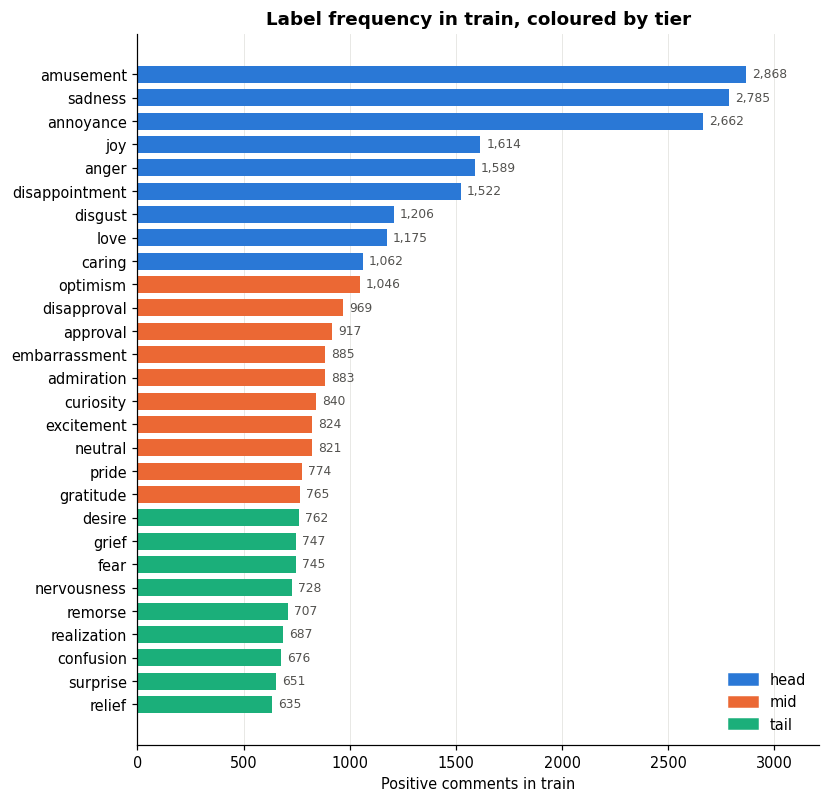

In [8]:
train_freq = pd.Series(Y['train'].sum(0), index=LABELS).sort_values(ascending=False)
ranked = list(train_freq.index)
TIERS = {'head': ranked[:9], 'mid': ranked[9:19], 'tail': ranked[19:]}
TIER_OF = {lab: t for t, labs in TIERS.items() for lab in labs}

display(pd.DataFrame([{'tier': t, 'n_labels': len(labs), 'labels': ', '.join(labs),
                       'train_count_min': int(train_freq[labs].min()), 'train_count_max': int(train_freq[labs].max())}
                      for t, labs in TIERS.items()]))
print(f'Most frequent : {train_freq.index[0]} ({train_freq.iloc[0]})')
print(f'Least frequent: {train_freq.index[-1]} ({train_freq.iloc[-1]})')
print(f'Imbalance ratio across labels (max/min train count): {train_freq.iloc[0] / train_freq.iloc[-1]:.1f}x')
print(f'Within-label imbalance: positives cover {100 * train_freq.min() / len(dfs["train"]):.1f}%–'
      f'{100 * train_freq.max() / len(dfs["train"]):.1f}% of train comments')

order = list(train_freq.index[::-1])
fig, ax = plt.subplots(figsize=(8, 8.4))
vals = train_freq[order]
ax.barh(order, vals, color=[TIER_COLORS[TIER_OF[l]] for l in order], height=0.72)
for y_pos, v in enumerate(vals):
    ax.text(v + vals.max() * 0.01, y_pos, f'{v:,}', va='center', fontsize=8, color='#52514e')
ax.set_xlim(0, vals.max() * 1.12)
ax.set_xlabel('Positive comments in train')
ax.set_title('Label frequency in train, coloured by tier')
ax.grid(axis='y', visible=False)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=TIER_COLORS[t]) for t in TIERS], list(TIERS),
          loc='lower right', frameon=False)
plt.show()

### 2.4 Label cardinality |Y|

,mean_|Y|,max_|Y|,label_density,%|Y|=1,%|Y|=2,%|Y|=3,%|Y|=>=4
train,1.908,5.0,0.068,32.853,46.615,17.634,2.898
val,1.916,5.0,0.068,32.865,45.692,18.780,2.662
test,1.907,5.0,0.068,33.624,45.767,17.417,3.193


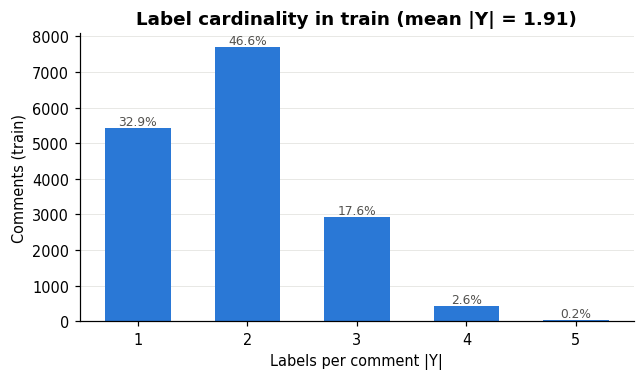

In [9]:
def bucket(n):
    return str(n) if n < 4 else '>=4'


rows = {}
for s in SPLITS:
    c = Y[s].sum(1)
    b = pd.Series([bucket(n) for n in c]).value_counts(normalize=True) * 100
    rows[s] = {'mean_|Y|': c.mean(), 'max_|Y|': c.max(), 'label_density': c.mean() / N_LABELS,
               **{f'%|Y|={k}': b.get(k, 0.0) for k in ['1', '2', '3', '>=4']}}
display(pd.DataFrame(rows).T.round(3))

dist = pd.Series(card_train).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(dist.index.astype(str), dist.values, color='#2a78d6', width=0.6)
for x, v in zip(dist.index.astype(str), dist.values):
    ax.text(x, v, f'{100 * v / dist.sum():.1f}%', ha='center', va='bottom', fontsize=8, color='#52514e')
ax.set_xlabel('Labels per comment |Y|'); ax.set_ylabel('Comments (train)')
ax.set_title(f'Label cardinality in train (mean |Y| = {card_train.mean():.2f})')
ax.grid(axis='x', visible=False)
plt.show()

### 2.5 Label co-occurrence and pairwise correlation (train)

Count = comments carrying both labels. Phi = Pearson correlation between two binary label columns (−1…1),
which corrects for label frequency. Lines separate the sentiment groups positive | ambiguous | negative | neutral.

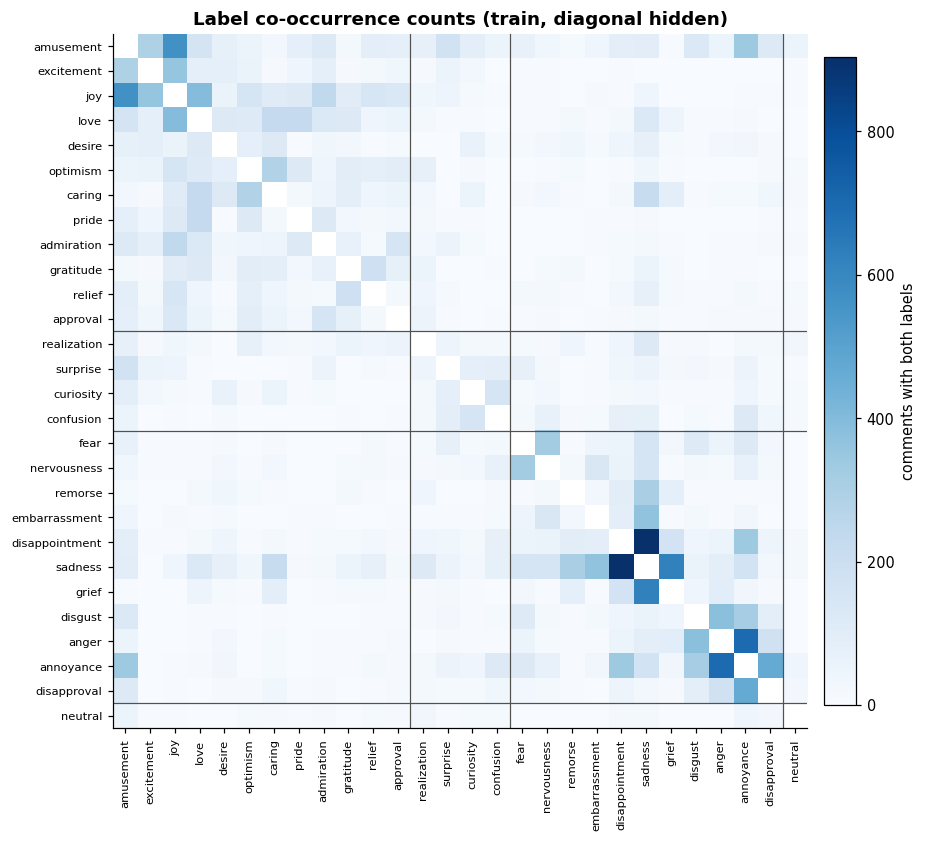

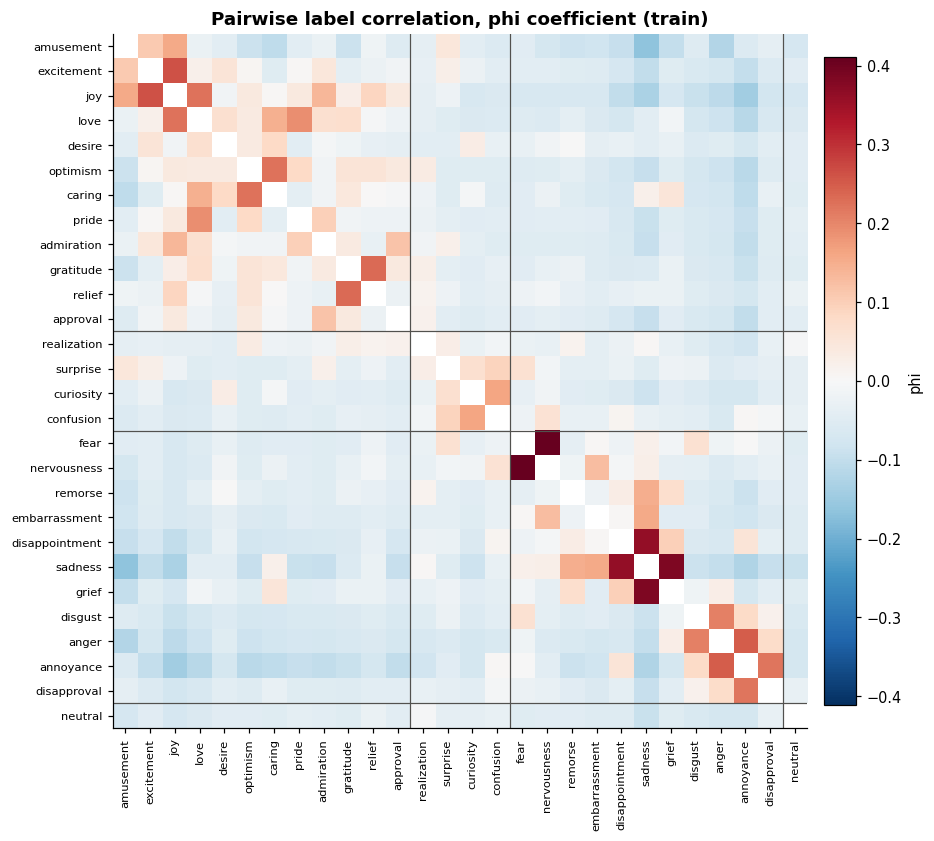

Top-15 co-occurring pairs (train)


,label_a,label_b,count,phi,same_group
0,disappointment,sadness,904,0.362,True
1,anger,annoyance,699,0.247,True
2,sadness,grief,620,0.384,True
3,amusement,joy,568,0.155,True
4,annoyance,disapproval,469,0.219,True
5,joy,love,395,0.222,True
6,disgust,anger,379,0.208,True
7,embarrassment,sadness,366,0.156,True
8,excitement,joy,359,0.261,True
9,amusement,annoyance,336,-0.055,False


Top-10 pairs by phi


,label_a,label_b,count,phi,same_group
0,fear,nervousness,322,0.411,True
1,sadness,grief,620,0.384,True
2,disappointment,sadness,904,0.362,True
3,excitement,joy,359,0.261,True
4,anger,annoyance,699,0.247,True
5,gratitude,relief,184,0.232,True
6,joy,love,395,0.222,True
7,optimism,caring,286,0.222,True
8,annoyance,disapproval,469,0.219,True
9,disgust,anger,379,0.208,True


Most negatively associated pairs


,label_a,label_b,count,phi,same_group
0,amusement,sadness,95,-0.166,False
1,joy,annoyance,5,-0.141,False
2,joy,sadness,36,-0.128,False
3,sadness,annoyance,167,-0.124,True
4,amusement,anger,56,-0.119,False
5,love,annoyance,10,-0.115,False
6,optimism,annoyance,3,-0.112,False
7,joy,anger,0,-0.107,False
8,caring,annoyance,14,-0.105,False
9,amusement,caring,24,-0.104,True


Share of the top-15 pairs inside one sentiment group: 93%


In [10]:
yt = Y['train'].astype(np.int32)
cooc_train = yt.T @ yt
phi = np.corrcoef(yt.T)
np.fill_diagonal(phi, np.nan)


def heatmap(mat, title, cmap, vmin, vmax, cbar_label):
    fig, ax = plt.subplots(figsize=(9.5, 8.2))
    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(N_LABELS)); ax.set_xticklabels(LABELS, rotation=90, fontsize=7.5)
    ax.set_yticks(range(N_LABELS)); ax.set_yticklabels(LABELS, fontsize=7.5)
    for b in (11.5, 15.5, 26.5):
        ax.axhline(b, color='#52514e', lw=0.8); ax.axvline(b, color='#52514e', lw=0.8)
    ax.grid(False); ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label=cbar_label)
    plt.show()


off = cooc_train.astype(float); np.fill_diagonal(off, np.nan)
heatmap(off, 'Label co-occurrence counts (train, diagonal hidden)', 'Blues', 0, np.nanmax(off), 'comments with both labels')
lim = np.nanmax(np.abs(phi))
heatmap(phi, 'Pairwise label correlation, phi coefficient (train)', 'RdBu_r', -lim, lim, 'phi')

pairs = pd.DataFrame([{'label_a': LABELS[i], 'label_b': LABELS[j], 'count': int(cooc_train[i, j]),
                       'phi': phi[i, j], 'same_group': GROUP[i] == GROUP[j]}
                      for i, j in combinations(range(N_LABELS), 2)])
top_pairs = pairs.sort_values('count', ascending=False).head(15).reset_index(drop=True)
print('Top-15 co-occurring pairs (train)'); display(top_pairs.round(3))
print('Top-10 pairs by phi'); display(pairs.sort_values('phi', ascending=False).head(10).reset_index(drop=True).round(3))
print('Most negatively associated pairs'); display(pairs.sort_values('phi').head(10).reset_index(drop=True).round(3))
print(f"Share of the top-15 pairs inside one sentiment group: {top_pairs['same_group'].mean():.0%}")

### 2.6 Text length

Whitespace-delimited tokens and characters (after Unicode NFC). Percentiles on train.

,split,unit,mean,min,p25,p50,p75,p90,p95,p99,max
0,train,tokens,16.1,1,7.0,11.0,19.0,32.0,44.0,84.0,214
1,train,chars,66.5,1,28.0,47.0,81.0,133.0,185.0,354.7,906
2,val,tokens,16.1,1,7.0,12.0,20.0,32.0,44.0,88.0,143
3,val,chars,66.5,1,27.0,47.0,81.0,130.5,187.8,363.4,641
4,test,tokens,16.8,1,7.0,11.0,20.0,35.0,47.0,90.7,171
5,test,chars,69.5,1,28.0,47.0,82.0,145.0,194.0,380.0,694


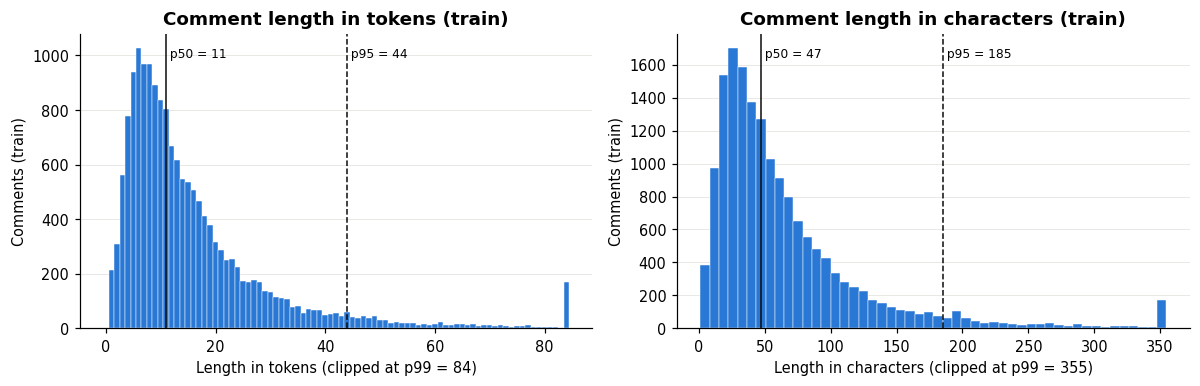

In [11]:
for s in SPLITS:
    t = dfs[s]['text'].astype(str).map(lambda x: unicodedata.normalize('NFC', x))
    dfs[s]['n_tokens'] = t.str.split().str.len()
    dfs[s]['n_chars'] = t.str.len()

pct = [25, 50, 75, 90, 95, 99]
display(pd.DataFrame([{'split': s, 'unit': col[2:], 'mean': dfs[s][col].mean(), 'min': dfs[s][col].min(),
                       **{f'p{p}': np.percentile(dfs[s][col], p) for p in pct}, 'max': dfs[s][col].max()}
                      for s in SPLITS for col in ('n_tokens', 'n_chars')]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, unit in [(axes[0], 'n_tokens', 'tokens'), (axes[1], 'n_chars', 'characters')]:
    v = dfs['train'][col]; cap = np.percentile(v, 99)
    bins = np.arange(0, cap + 2) - 0.5 if col == 'n_tokens' else 50
    ax.hist(v.clip(upper=cap), bins=bins, color='#2a78d6', edgecolor='white', linewidth=0.3)
    for p, ls in [(50, '-'), (95, '--')]:
        q = np.percentile(v, p)
        ax.axvline(q, color='#0b0b0b', lw=1, ls=ls)
        ax.text(q, ax.get_ylim()[1] * 0.92, f' p{p} = {q:.0f}', fontsize=8)
    ax.set_xlabel(f'Length in {unit} (clipped at p99 = {cap:.0f})'); ax.set_ylabel('Comments (train)')
    ax.set_title(f'Comment length in {unit} (train)'); ax.grid(axis='x', visible=False)
fig.tight_layout(); plt.show()

### 2.7 Vietnamese informal-text phenomena

| Phenomenon | Detector |
|---|---|
| Emoji | `emoji.emoji_list` (variation selector removed, so ❤ and ❤️ count as one) |
| Text emoticon | `:)`, `:))`, `=))`, `:(`, `:v`, `:D`, `<3`, `^^`, `xD`, `T_T`, `-_-` |
| Teencode | whole alphabetic token in a small high-precision lexicon (below); rates are lower bounds |
| Letter elongation | the same letter 3+ times in a row (`cườiiii`) |
| Repeated punctuation | `!!!`, `???`, `...` (3+) |
| No diacritics | ≥ 3 alphabetic tokens and every letter is plain ASCII (also catches English comments) |
| URL / mention | `http…`, `www.`, `@name` |

Percent of comments (last row: mean count)


,train,val,test
has_emoji,24.86,24.59,25.93
has_emoticon,10.59,10.89,9.53
has_teencode,16.77,17.42,16.50
has_elongation,2.07,2.08,2.23
has_repeat_punct,4.92,4.60,4.31
no_diacritics,0.76,0.53,0.77
has_url_or_mention,3.59,2.95,3.48
emoji_only,0.77,1.02,0.77
%_with_>=2_emoji,9.68,9.68,8.71
mean_emoji_per_comment,0.47,0.51,0.47


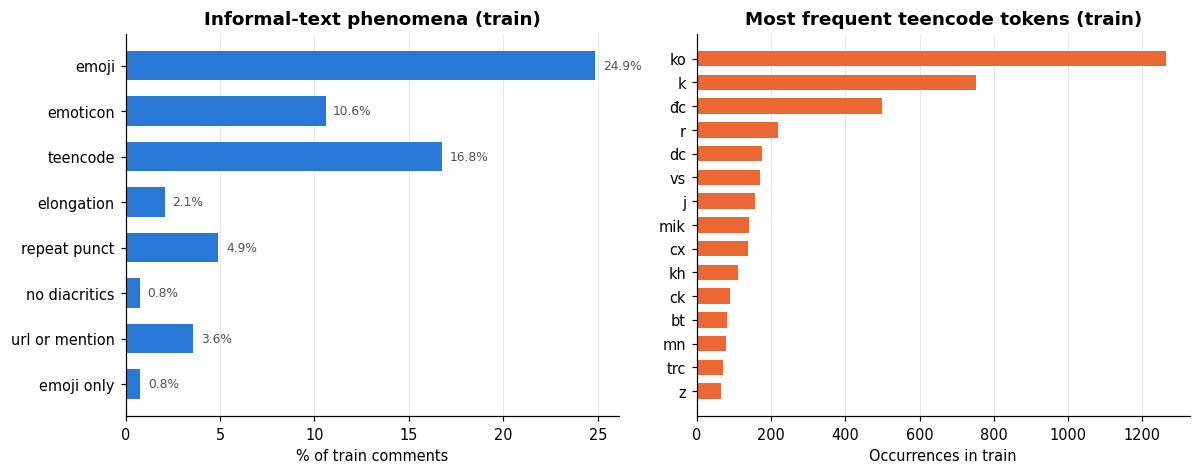

Top-20 emoji (train)


,emoji,count,name
0,😂,882,face_with_tears_of_joy
1,🤣,530,rolling_on_the_floor_laughing
2,❤,477,red_heart
3,😭,394,loudly_crying_face
4,🇻🇳,366,Vietnam
5,🥰,351,smiling_face_with_hearts
6,😌,234,relieved_face
7,🥺,200,pleading_face
8,😅,199,grinning_face_with_sweat
9,👍,198,thumbs_up


Emoji / teencode rate per label (train), sorted by emoji rate


,love,pride,amusement,embarrassment,relief,joy,grief,remorse,sadness,excitement,...,confusion,surprise,admiration,annoyance,disgust,realization,disapproval,curiosity,anger,neutral
%_with_emoji,48.8,44.4,40.8,38.4,38.3,37.1,35.1,33.5,31.7,30.9,...,19.8,19.0,18.5,16.2,15.5,13.8,12.9,12.0,11.4,7.1
%_with_teencode,8.6,16.1,12.2,33.6,21.1,8.7,20.3,28.3,20.4,8.6,...,28.6,10.3,7.6,19.9,11.2,19.5,22.1,21.9,17.5,15.5


In [12]:
TEENCODE = {'ko', 'k', 'kh', 'hok', 'hong', 'khum', 'dc', 'đc', 'đk', 'j', 'vs', 'ns', 'thik', 'mk', 'mik',
            'ck', 'vk', 'z', 'zậy', 'r', 'bt', 'bít', 'oke', 'okela', 'cx', 'ntn', 'ms', 'nma', 'trc', 'ib',
            'mn', 'mng', 'ny', 'ae', 'bh', 'tks', 'pk', 'ak', 'ạk'}
EMOTICON = re.compile(r"(?:[:;=8][\-']?[)(DPpvV3\]\[]+|<3+|\^\^+|\bx[dD]\b|T_T|-_-)")
ELONGATION = re.compile(r'([^\W\d_])\1{2,}')
REPEAT_PUNCT = re.compile(r'([!?.])\1{2,}')
URL_OR_MENTION = re.compile(r'https?://\S+|www\.\S+|@\w+')
PUNCT = ''.join(chr(i) for i in range(0x110000) if unicodedata.category(chr(i)).startswith('P'))


def list_emoji(text):
    return [e['emoji'].replace('️', '') for e in emoji.emoji_list(text)]


def alpha_words(text):
    # Remove emoji (often glued to words) and keep whole alphabetic tokens, so '100k' is not the teencode 'k'.
    words = [w.strip(PUNCT) for w in emoji.replace_emoji(text, ' ').lower().split()]
    return [w for w in words if w.isalpha()]


def text_features(text):
    t = unicodedata.normalize('NFC', str(text))
    words = alpha_words(t)
    ems = list_emoji(t)
    teen = [w for w in words if w in TEENCODE]
    return {'n_emoji': len(ems), 'has_emoji': len(ems) > 0, 'has_emoticon': bool(EMOTICON.search(t)),
            'has_teencode': len(teen) > 0, 'has_elongation': bool(ELONGATION.search(t)),
            'has_repeat_punct': bool(REPEAT_PUNCT.search(t)),
            'no_diacritics': len(words) >= 3 and all(ord(ch) < 128 for ch in t if ch.isalpha()),
            'has_url_or_mention': bool(URL_OR_MENTION.search(t)),
            'emoji_only': len(ems) > 0 and len(words) == 0, '_emojis': ems, '_teen': teen}


feats = {s: pd.DataFrame([text_features(x) for x in dfs[s]['text']]) for s in SPLITS}
flag_cols = ['has_emoji', 'has_emoticon', 'has_teencode', 'has_elongation', 'has_repeat_punct',
             'no_diacritics', 'has_url_or_mention', 'emoji_only']
phen = pd.DataFrame({s: feats[s][flag_cols].mean() * 100 for s in SPLITS})
phen.loc['%_with_>=2_emoji'] = [100 * (feats[s]['n_emoji'] >= 2).mean() for s in SPLITS]
phen.loc['mean_emoji_per_comment'] = [feats[s]['n_emoji'].mean() for s in SPLITS]
print('Percent of comments (last row: mean count)'); display(phen.round(2))

ft = feats['train']
top_emoji = pd.DataFrame(Counter(e for l in ft['_emojis'] for e in l).most_common(20), columns=['emoji', 'count'])
top_emoji['name'] = [emoji.demojize(e).strip(':') for e in top_emoji['emoji']]
top_teen = pd.DataFrame(Counter(w for l in ft['_teen'] for w in l).most_common(15), columns=['teencode', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
pr = phen.loc[flag_cols, 'train'][::-1]
axes[0].barh([c.replace('has_', '').replace('_', ' ') for c in pr.index], pr.values, color='#2a78d6', height=0.65)
for y_pos, v in enumerate(pr.values):
    axes[0].text(v + 0.4, y_pos, f'{v:.1f}%', va='center', fontsize=8, color='#52514e')
axes[0].set_xlabel('% of train comments'); axes[0].set_title('Informal-text phenomena (train)')
axes[0].grid(axis='y', visible=False)
axes[1].barh(top_teen['teencode'][::-1], top_teen['count'][::-1], color='#eb6834', height=0.65)
axes[1].set_xlabel('Occurrences in train'); axes[1].set_title('Most frequent teencode tokens (train)')
axes[1].grid(axis='y', visible=False)
fig.tight_layout(); plt.show()
print('Top-20 emoji (train)'); display(top_emoji)

by_label = pd.DataFrame({'%_with_emoji': [100 * ft.loc[Y['train'][:, c] == 1, 'has_emoji'].mean() for c in range(N_LABELS)],
                         '%_with_teencode': [100 * ft.loc[Y['train'][:, c] == 1, 'has_teencode'].mean() for c in range(N_LABELS)]},
                        index=LABELS)
print('Emoji / teencode rate per label (train), sorted by emoji rate'); display(by_label.sort_values('%_with_emoji', ascending=False).round(1).T)

In [13]:
rng_examples = np.random.default_rng(SEED)


def show_examples(mask, title, k=4, max_chars=150):
    idx = np.flatnonzero(np.asarray(mask))
    print(f'--- {title}: {len(idx)} train comments ({len(idx) / len(mask):.1%}) ---')
    for i in rng_examples.choice(idx, size=min(k, len(idx)), replace=False):
        print(f"  {comment_text(dfs['train'], i, max_chars)}  ->  {[LABELS[j] for j in dfs['train']['label_idx'].iloc[i]]}")
    print()


show_examples(ft['has_teencode'], 'teencode')
show_examples(ft['n_emoji'] >= 3, 'emoji-heavy (>= 3 emoji)')
show_examples(ft['emoji_only'], 'emoji only')
show_examples(ft['has_elongation'], 'letter elongation')
show_examples(ft['no_diacritics'], 'no diacritics / non-Vietnamese')
show_examples(card_train >= 4, 'high cardinality |Y| >= 4')

--- teencode: 2773 train comments (16.8%) ---
  [comment id tik021391]  ->  ['confusion']
  [comment id 11793]  ->  ['amusement', 'joy']
  [comment id tik022201]  ->  ['nervousness', 'embarrassment']
  [comment id tik011923]  ->  ['remorse']

--- emoji-heavy (>= 3 emoji): 899 train comments (5.4%) ---
  [comment id 4250]  ->  ['disgust', 'anger']
  [comment id x001517]  ->  ['love', 'relief']
  [comment id 275]  ->  ['amusement']
  [comment id you004125]  ->  ['amusement', 'excitement', 'pride', 'admiration', 'joy']

--- emoji only: 128 train comments (0.8%) ---
  [comment id you004286]  ->  ['love', 'amusement', 'relief', 'joy']
  [comment id 17093]  ->  ['love', 'grief', 'sadness']
  [comment id tik011907]  ->  ['approval', 'optimism']
  [comment id tik008606]  ->  ['amusement', 'excitement', 'joy']

--- letter elongation: 343 train comments (2.1%) ---
  [comment id tik017835]  ->  ['curiosity', 'amusement']
  [comment id you002875]  ->  ['joy', 'relief']
  [comment id 18555]  ->  ['

### 2.8 Train / validation / test partition protocol

The dataset ships with an official split (≈ 80 / 10 / 10), the protocol of the original paper. It is kept unchanged so that
results are comparable with the paper and no comment can move between splits. The table checks that each label has a
similar prevalence in the three splits, which is what a stratified multi-label split should give.

,amusement,excitement,joy,love,desire,optimism,caring,pride,admiration,gratitude,...,remorse,embarrassment,disappointment,sadness,grief,disgust,anger,annoyance,disapproval,neutral
train,17.35,4.98,9.76,7.11,4.61,6.33,6.42,4.68,5.34,4.63,...,4.28,5.35,9.21,16.85,4.52,7.30,9.61,16.10,5.86,4.97
val,15.83,4.40,8.13,7.16,4.94,5.91,6.34,4.21,5.18,4.65,...,4.65,6.63,10.21,17.13,4.70,7.94,8.95,16.02,5.95,4.55
test,18.09,4.74,9.87,6.92,3.87,6.87,7.26,4.16,4.89,5.22,...,4.21,5.18,9.53,16.69,4.16,6.82,9.14,16.59,5.42,5.61
max_gap_pp,2.27,0.58,1.74,0.25,1.07,0.96,0.92,0.52,0.46,0.60,...,0.44,1.45,1.01,0.44,0.53,1.12,0.66,0.57,0.54,1.06
val_positives,327.00,91.00,168.00,148.00,102.00,122.00,131.00,87.00,107.00,96.00,...,96.00,137.00,211.00,354.00,97.00,164.00,185.00,331.00,123.00,94.00
test_positives,374.00,98.00,204.00,143.00,80.00,142.00,150.00,86.00,101.00,108.00,...,87.00,107.00,197.00,345.00,86.00,141.00,189.00,343.00,112.00,116.00


Largest prevalence gap between splits: 2.27 pp (amusement)
Fewest validation positives: 58 (relief)


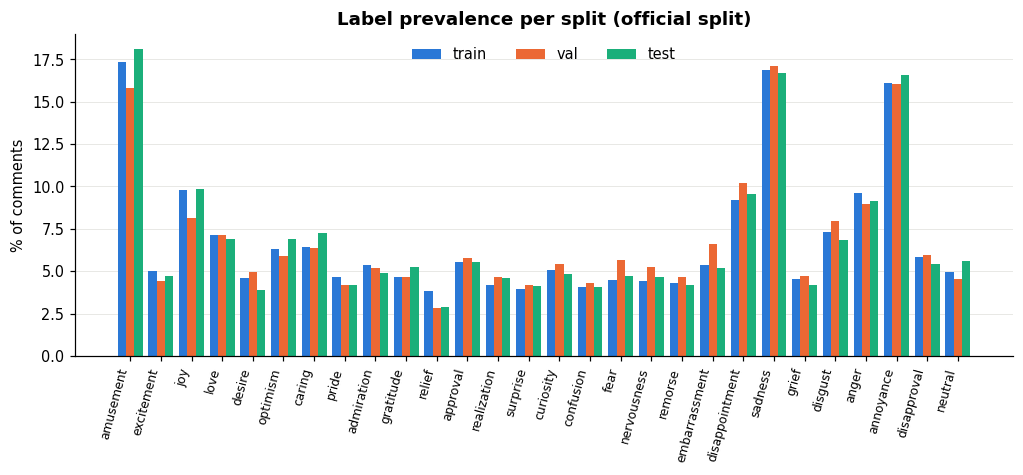

In [14]:
prev = pd.DataFrame({s: 100 * Y[s].mean(0) for s in SPLITS}, index=LABELS)
prev['max_gap_pp'] = prev[SPLITS].max(axis=1) - prev[SPLITS].min(axis=1)
prev['val_positives'] = Y['val'].sum(0)
prev['test_positives'] = Y['test'].sum(0)
display(prev.round(2).T)
print(f"Largest prevalence gap between splits: {prev['max_gap_pp'].max():.2f} pp ({prev['max_gap_pp'].idxmax()})")
print('Fewest validation positives:', int(prev['val_positives'].min()), f"({prev['val_positives'].idxmin()})")

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(N_LABELS); w = 0.27
for k, (s, col) in enumerate(zip(SPLITS, ['#2a78d6', '#eb6834', '#1baf7a'])):
    ax.bar(x + (k - 1) * w, prev[s], width=w, color=col, label=s)
ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=75, ha='right', fontsize=8)
ax.set_ylabel('% of comments'); ax.set_title('Label prevalence per split (official split)')
ax.legend(frameon=False, ncol=3); ax.grid(axis='x', visible=False)
plt.show()

In [15]:
# Split index files (comment ids only, safe to publish) and SHA-256 checksums of the source CSVs
import hashlib

SPLIT_DIR = CODE_DIR / 'splits'
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
sums = []
for s in SPLITS:
    (SPLIT_DIR / f'{s}_ids.txt').write_text('\n'.join(dfs[s]['id']) + '\n', encoding='utf-8')
    sums.append(f"{hashlib.sha256((CORPUS_DIR / f'{s}.csv').read_bytes()).hexdigest()}  {s}.csv")
(SPLIT_DIR / 'SHA256SUMS.txt').write_text('\n'.join(sums) + '\n', encoding='utf-8')
print('Wrote', ', '.join(f'{s}_ids.txt ({len(dfs[s]):,} ids)' for s in SPLITS), 'and SHA256SUMS.txt to', SPLIT_DIR)
print('\n'.join(sums))

Wrote train_ids.txt (16,531 ids), val_ids.txt (2,066 ids), test_ids.txt (2,067 ids) and SHA256SUMS.txt to /content/drive/MyDrive/ATI_data/62FIT4ATI-CLC02_G02_P02/code/splits
9abcb2b7d9fadd9da043a3af43e8ee569f7099d87d20daf39a69e7e1a76c5624  train.csv
d3a473a65bf10d3d07423306a4324e94c9979d42d58f6a05cceb4cc1cc4fcab0  val.csv
620814a67ad5297cdcdac6369dbb223b4e95030b7b525d4466302f0288418e33  test.csv


## 3. Preprocessing Pipeline

The same text pipeline feeds all three models, so differences between models are not caused by different inputs:

1. Unicode **NFC** normalisation.
2. **Emoji → English name** with `emoji.demojize` (😂 → `face_with_tears_of_joy`). Section 3.2 shows why: PhoBERT's vocabulary
   maps many raw emoji to `<unk>`, which would erase their emotional signal.
3. **Elongation reduction:** a letter repeated 3+ times → one letter (`cườiiii` → `cười`); a punctuation / symbol repeated 3+ times
   → two (`:))))` → `:))`, `!!!!` → `!!`). Digits are untouched.
4. **Word segmentation** with `underthesea.word_tokenize` (`Hà nội` → `Hà_nội`). PhoBERT was pre-trained on word-segmented text.
5. Model-specific: TF-IDF and BiLSTM lowercase the segmented text; PhoBERT keeps the case.

Teencode is **not** normalised, so Q4 can measure how each model copes with it.


### 3.1 Text normalisation and word segmentation

`normalize_text` applies steps 1–3 to every comment, then `underthesea.word_tokenize` segments it (step 4).
The result is stored in `text_seg`, the shared input of all three models.

In [16]:
LETTER_RUN = re.compile(r'([^\W\d_])\1{2,}')
SYMBOL_RUN = re.compile(r'([^\w\s])\1{2,}')


def normalize_text(text):
    t = unicodedata.normalize('NFC', str(text))
    t = emoji.demojize(t, delimiters=(' ', ' '))
    t = LETTER_RUN.sub(r'\1', t)
    t = SYMBOL_RUN.sub(r'\1\1', t)
    return re.sub(r'\s+', ' ', t).strip()


t0 = time.time()
for s in SPLITS:
    dfs[s]['text_seg'] = [word_tokenize(normalize_text(x), format='text') for x in tqdm(dfs[s]['text'], desc=s, leave=False)]
print(f'Preprocessing done in {time.time() - t0:.0f}s')

if SHOW_COMMENT_TEXT:
    print('\nExamples (local inspection only):')
    for i in [0, 1, 2]:
        print('  raw :', repr(dfs['train']['text'].iloc[i][:120]))
        print('  seg :', repr(dfs['train']['text_seg'].iloc[i][:120]))

train:   0%|          | 0/16531 [00:00<?, ?it/s]

val:   0%|          | 0/2066 [00:00<?, ?it/s]

test:   0%|          | 0/2067 [00:00<?, ?it/s]

Preprocessing done in 47s


### 3.2 PhoBERT tokenizer check: unknown tokens and length budget

Compares the `<unk>` rate of the PhoBERT tokenizer on segmented **raw** text (emoji kept) versus the pipeline above,
and sets PhoBERT's `max_len` from the train length distribution (rounded up to a multiple of 8, capped at 256).

In [17]:
PHOBERT_NAME = CFG['phobert']['checkpoint']
tokenizer = AutoTokenizer.from_pretrained(PHOBERT_NAME)


def unk_stats(texts):
    ids = tokenizer(list(texts), add_special_tokens=False)['input_ids']
    n_tok = sum(len(x) for x in ids)
    n_unk = sum(x.count(tokenizer.unk_token_id) for x in ids)
    return {'unk_%_of_tokens': 100 * n_unk / n_tok,
            '%_comments_with_unk': 100 * np.mean([tokenizer.unk_token_id in x for x in ids]), 'ids': ids}


raw_seg = [word_tokenize(unicodedata.normalize('NFC', str(x)), format='text') for x in tqdm(dfs['train']['text'], leave=False)]
st_raw, st_clean = unk_stats(raw_seg), unk_stats(dfs['train']['text_seg'])
display(pd.DataFrame({'raw text (emoji kept)': {k: v for k, v in st_raw.items() if k != 'ids'},
                      'pipeline (emoji -> name)': {k: v for k, v in st_clean.items() if k != 'ids'}}).round(2))

sub_len = np.array([len(x) + 2 for x in st_clean['ids']])          # + <s> and </s>
p = CFG['phobert']['len_percentile']
PHOBERT_MAX_LEN = int(min(CFG['phobert']['max_len_cap'], int(np.ceil(np.percentile(sub_len, p) / 8) * 8)))
print(f'PhoBERT sub-word length (train): p50={np.percentile(sub_len, 50):.0f}, p95={np.percentile(sub_len, 95):.0f}, '
      f'p{p}={np.percentile(sub_len, p):.0f}, max={sub_len.max()}')
print(f'PhoBERT max_len = {PHOBERT_MAX_LEN} -> truncates {100 * (sub_len > PHOBERT_MAX_LEN).mean():.2f}% of train comments')

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

  0%|          | 0/16531 [00:00<?, ?it/s]

,raw text (emoji kept),pipeline (emoji -> name)
unk_%_of_tokens,3.41,0.21
%_comments_with_unk,27.03,2.92


PhoBERT sub-word length (train): p50=16, p95=55, p99=95, max=366
PhoBERT max_len = 96 -> truncates 0.96% of train comments


## 4. Part B — Required Models

### 4.0 Shared evaluation and run management

* `compute_metrics` implements every metric of Part C. A label is predicted when its probability ≥ τ (default 0.5).
* `run_or_load` saves each model's selected weights and its **validation and test probabilities** to
  (`RUN_ROOT/<model>/`). If a run with the same configuration is already there, it is loaded instead of retrained.

In [18]:
THR = CFG['threshold']


def compute_metrics(y_true, probs, thr=THR):
    y_pred = (probs >= thr).astype(int)
    return {'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'micro_f1': f1_score(y_true, y_pred, average='micro', zero_division=0),
            'hamming_loss': hamming_loss(y_true, y_pred),
            'lrap': label_ranking_average_precision_score(y_true, probs),
            'mAP': average_precision_score(y_true, probs, average='macro')}


def jsonable(obj):
    return json.loads(json.dumps(obj, default=lambda v: v.item() if hasattr(v, 'item') else str(v)))


def run_or_load(name, cfg_used, train_fn):
    run_dir = RUN_ROOT / name
    npz_path, meta_path = run_dir / 'probs.npz', run_dir / 'run.json'
    cfg_used = jsonable(cfg_used)
    if not RETRAIN and npz_path.exists() and meta_path.exists():
        meta = json.loads(meta_path.read_text())
        if meta['config'] == cfg_used:
            z = np.load(npz_path)
            assert list(z['ids_val']) == list(dfs['val']['id']) and list(z['ids_test']) == list(dfs['test']['id'])
            print(f'Loaded saved run from {run_dir} (set RETRAIN = True to retrain).')
            return {**meta, 'probs_val': z['probs_val'], 'probs_test': z['probs_test']}
        print(f'Saved run in {run_dir} used a different configuration -> retraining.')
    run_dir.mkdir(parents=True, exist_ok=True)
    out = train_fn(run_dir)
    np.savez_compressed(npz_path, ids_val=dfs['val']['id'].to_numpy(str), ids_test=dfs['test']['id'].to_numpy(str),
                        probs_val=out.pop('probs_val'), probs_test=out.pop('probs_test'))
    meta = jsonable({'model': name, 'config': cfg_used, **out})
    meta_path.write_text(json.dumps(meta, indent=2))
    z = np.load(npz_path)
    print(f'Saved run to {run_dir}')
    return {**meta, 'probs_val': z['probs_val'], 'probs_test': z['probs_test']}


def show_selection(res):
    print(f"Selected: {res['selected']}  | val Macro-F1 = {res['selected_val_macro_f1']:.4f}")
    print(f"Parameters: {res['n_params']:,}  | training time of selected config: {res['train_time_s'] / 60:.1f} min "
          f"| whole search: {res['search_time_s'] / 60:.1f} min")
    g = pd.DataFrame(res['grid'])
    display(g.round({c: 4 for c in g.columns if c != 'lr'}))
    if res.get('history'):
        h = pd.DataFrame(res['history'])
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
        for key, grp in h.groupby('run'):
            axes[0].plot(grp['epoch'], grp['train_loss'], marker='o', ms=3, label=key)
            axes[1].plot(grp['epoch'], grp['val_macro_f1'], marker='o', ms=3, label=key)
        axes[0].set_title('Training loss (BCE)'); axes[1].set_title('Validation Macro-F1 (τ = 0.5)')
        for ax in axes:
            ax.set_xlabel('Epoch'); ax.legend(frameon=False, fontsize=8)
        fig.tight_layout(); plt.show()


results = {}
Y_train, Y_val, Y_test = Y['train'], Y['val'], Y['test']

### 4.1 Model 1 — TF-IDF + One-vs-Rest Logistic Regression

Word 1–2-grams + character 2–5-grams (`char_wb`) on the lowercased segmented text, fitted on **train only**.
One logistic regression per label. Grid on validation Macro-F1: C ∈ {0.5, 1, 4, 10} × class_weight ∈ {None, balanced}.

In [19]:
def train_tfidf(run_dir):
    c = CFG['tfidf']
    t0 = time.time()
    vec = FeatureUnion([
        ('word', TfidfVectorizer(analyzer='word', token_pattern=r'\S+', ngram_range=tuple(c['word_ngram']),
                                 min_df=c['min_df'], sublinear_tf=c['sublinear_tf'], lowercase=True)),
        ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=tuple(c['char_ngram']),
                                 min_df=c['min_df'], sublinear_tf=c['sublinear_tf'], lowercase=True))])
    X = {s: (vec.fit_transform if s == 'train' else vec.transform)(dfs[s]['text_seg']).tocsr() for s in SPLITS}
    for m in X.values():   # canonical CSR: the parallel per-label fits must not modify the shared matrix
        m.sum_duplicates(); m.sort_indices()
    vec_time = time.time() - t0
    print(f'TF-IDF features: {X["train"].shape[1]:,}  ({vec_time:.0f}s)')

    grid, best = [], None
    for C in c['C_grid']:
        for cw in c['class_weight_grid']:
            t1 = time.time()
            clf = OneVsRestClassifier(LogisticRegression(C=C, class_weight=cw, solver=c['solver'],
                                                         max_iter=c['max_iter']), n_jobs=-1).fit(X['train'], Y_train)
            fit_time = time.time() - t1
            f1 = compute_metrics(Y_val, clf.predict_proba(X['val']))['macro_f1']
            grid.append({'C': C, 'class_weight': str(cw), 'val_macro_f1': f1, 'fit_time_s': fit_time})
            print(f'  C={C:<4} class_weight={str(cw):<9} val Macro-F1={f1:.4f}  ({fit_time:.0f}s)')
            if best is None or f1 > best[0]:
                best = (f1, clf, {'C': C, 'class_weight': str(cw)}, fit_time)
    f1, clf, sel, fit_time = best
    joblib.dump({'vectorizer': vec, 'classifier': clf}, run_dir / 'model.joblib')
    return {'selected': sel, 'selected_val_macro_f1': f1, 'grid': grid,
            'n_params': int(sum(e.coef_.size + e.intercept_.size for e in clf.estimators_)),
            'train_time_s': vec_time + fit_time, 'search_time_s': time.time() - t0,
            'probs_val': clf.predict_proba(X['val']), 'probs_test': clf.predict_proba(X['test'])}


results['tfidf_lr'] = run_or_load('tfidf_lr', CFG['tfidf'], train_tfidf)
show_selection(results['tfidf_lr'])

Loaded saved run from /content/drive/MyDrive/ATI_data/62FIT4ATI-CLC02_G02_P02/code/runs/tfidf_lr (set RETRAIN = True to retrain).
Selected: {'C': 4, 'class_weight': 'balanced'}  | val Macro-F1 = 0.5298
Parameters: 2,370,340  | training time of selected config: 0.6 min | whole search: 3.5 min


,C,class_weight,val_macro_f1,fit_time_s
0,0.5,None,0.2948,22.9250
1,0.5,balanced,0.5047,20.3907
2,1.0,None,0.3588,18.2104
3,1.0,balanced,0.5192,22.5389
4,4.0,None,0.4372,24.1117
5,4.0,balanced,0.5298,31.9091
6,10.0,None,0.4562,24.6342
7,10.0,balanced,0.5284,34.6464


### 4.2 Shared PyTorch training loop (BiLSTM and PhoBERT)

BCE loss over the 28 independent sigmoid outputs:
$\mathcal{L} = -\frac{1}{C}\sum_{c=1}^{C}\left[y_c \log p_c + (1-y_c)\log(1-p_c)\right]$ (`BCEWithLogitsLoss`).
After each epoch the model is scored on validation Macro-F1 at τ = 0.5; the best epoch is kept and training stops after
`patience` epochs without improvement.

In [20]:
@torch.no_grad()
def predict_probs(model, loader, forward, amp):
    model.eval()
    out = []
    for batch in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=amp):
            logits = forward(model, batch)
        out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)


def train_torch(model, train_loader, val_loader, forward, optimizer, scheduler, max_epochs, patience, grad_clip, run_label, amp):
    loss_fn = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=amp)
    best_f1, best_state, best_epoch, bad, history = -1.0, None, 0, 0, []
    t_start = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train(); t0 = time.time(); total, n = 0.0, 0
        for batch in tqdm(train_loader, leave=False, desc=f'{run_label} epoch {epoch}'):
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=amp):
                logits = forward(model, batch)
            loss = loss_fn(logits.float(), batch['labels'].to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer); scaler.update()
            if scheduler is not None:
                scheduler.step()
            total += loss.item() * len(batch['labels']); n += len(batch['labels'])
        val_m = compute_metrics(Y_val, predict_probs(model, val_loader, forward, amp))
        history.append({'run': run_label, 'epoch': epoch, 'train_loss': total / n,
                        'val_macro_f1': val_m['macro_f1'], 'val_micro_f1': val_m['micro_f1'], 'epoch_s': time.time() - t0})
        print(f"  {run_label} epoch {epoch:2d}: train_loss={total / n:.4f}  val Macro-F1={val_m['macro_f1']:.4f}  "
              f"Micro-F1={val_m['micro_f1']:.4f}  ({time.time() - t0:.0f}s)")
        if val_m['macro_f1'] > best_f1:
            best_f1, best_epoch, bad = val_m['macro_f1'], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f'  early stop: no improvement for {patience} epochs')
                break
    model.load_state_dict(best_state)
    return {'best_val_macro_f1': best_f1, 'best_epoch': best_epoch, 'history': history,
            'train_time_s': time.time() - t_start}


def make_loader(dataset, batch_size, shuffle, collate):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, collate_fn=collate, generator=g)


class ListDataset(Dataset):
    def __init__(self, items):
        self.items = items
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.items[i]

### 4.3 Model 2 — BiLSTM

Vocabulary from train tokens (min frequency 2; others → `<unk>`), randomly initialised 300-d embeddings,
2-layer bidirectional LSTM (256 units per direction), max-pooling over time, dropout 0.3, linear layer → 28 logits.
`max_len` = 99th percentile of train token length. Adam (lr 1e-3), batch 64, gradient clipping 1.0, full precision.
Fixed configuration; epoch selected on validation.

Loaded saved run from /content/drive/MyDrive/ATI_data/62FIT4ATI-CLC02_G02_P02/code/runs/bilstm (set RETRAIN = True to retrain).
Selected: {'lr': 0.001, 'best_epoch': 14, 'max_len': 77, 'vocab_size': 7325}  | val Macro-F1 = 0.4934
Parameters: 4,931,608  | training time of selected config: 2.2 min | whole search: 2.2 min


,lr,best_epoch,val_macro_f1
0,0.001,14,0.4934


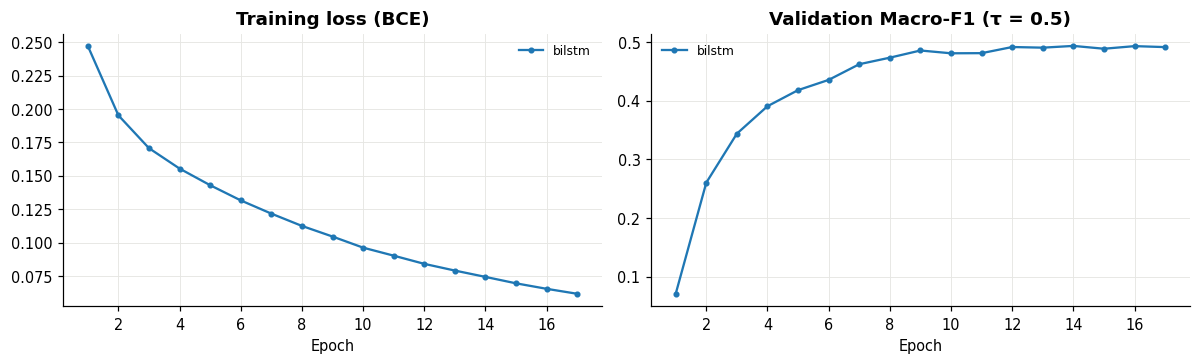

In [21]:
def build_bilstm_data():
    c = CFG['bilstm']
    toks = {s: [t.lower().split() for t in dfs[s]['text_seg']] for s in SPLITS}
    freq = Counter(w for sent in toks['train'] for w in sent)
    vocab = {'<pad>': 0, '<unk>': 1}
    for w, n in freq.most_common():
        if n >= c['min_freq']:
            vocab[w] = len(vocab)
    max_len = int(np.percentile([len(t) for t in toks['train']], c['len_percentile']))
    data = {s: [([vocab.get(w, 1) for w in sent[:max_len]], Y[s][i].astype(np.float32))
                for i, sent in enumerate(toks[s])] for s in SPLITS}
    oov = np.mean([w not in vocab for sent in toks['val'] for w in sent]) * 100
    print(f'Vocabulary: {len(vocab):,} | max_len: {max_len} | val OOV token rate: {oov:.2f}%')
    return vocab, max_len, data


def collate_bilstm(batch):
    lengths = torch.tensor([len(ids) for ids, _ in batch])
    ids = torch.zeros(len(batch), int(lengths.max()), dtype=torch.long)
    for i, (seq, _) in enumerate(batch):
        ids[i, :len(seq)] = torch.tensor(seq)
    return {'ids': ids, 'lengths': lengths, 'labels': torch.tensor(np.stack([y for _, y in batch]))}


class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, layers, dropout, n_labels):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(2 * hidden, n_labels)

    def forward(self, ids, lengths):
        x = self.drop(self.emb(ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        h = h.masked_fill((ids == 0).unsqueeze(-1), float('-inf')).max(dim=1).values   # max-pool over real tokens
        return self.out(self.drop(h))


def bilstm_forward(model, batch):
    return model(batch['ids'].to(DEVICE), batch['lengths'])


def train_bilstm(run_dir):
    c = CFG['bilstm']
    vocab, max_len, data = build_bilstm_data()
    seed_everything()
    model = BiLSTMClassifier(len(vocab), c['emb_dim'], c['hidden'], c['layers'], c['dropout'], N_LABELS).to(DEVICE)
    loaders = {s: make_loader(ListDataset(data[s]), c['batch_size'], s == 'train', collate_bilstm) for s in SPLITS}
    optimizer = torch.optim.Adam(model.parameters(), lr=c['lr'])
    r = train_torch(model, loaders['train'], loaders['val'], bilstm_forward, optimizer, None,
                    c['max_epochs'], c['patience'], c['grad_clip'], 'bilstm', amp=False)
    torch.save({'state_dict': model.state_dict(), 'vocab': vocab, 'max_len': max_len}, run_dir / 'model_best.pt')
    return {'selected': {'lr': c['lr'], 'best_epoch': r['best_epoch'], 'max_len': max_len, 'vocab_size': len(vocab)},
            'selected_val_macro_f1': r['best_val_macro_f1'],
            'grid': [{'lr': c['lr'], 'best_epoch': r['best_epoch'], 'val_macro_f1': r['best_val_macro_f1']}],
            'history': r['history'], 'n_params': sum(p.numel() for p in model.parameters()),
            'train_time_s': r['train_time_s'], 'search_time_s': r['train_time_s'],
            'probs_val': predict_probs(model, loaders['val'], bilstm_forward, False),
            'probs_test': predict_probs(model, loaders['test'], bilstm_forward, False)}


results['bilstm'] = run_or_load('bilstm', CFG['bilstm'], train_bilstm)
show_selection(results['bilstm'])

### 4.4 Model 3 — PhoBERT fine-tuning (independent sigmoid head + BCE)

`AutoModelForSequenceClassification` with 28 outputs and `problem_type='multi_label_classification'`
(classification head on the `<s>` token → 28 independent logits → sigmoid). Input = word-segmented text, cased,
truncated to `PHOBERT_MAX_LEN` (Section 3.2). AdamW, weight decay 0.01, linear schedule with 10 % warm-up, batch 32,
fp16 on GPU, gradient clipping 1.0, early stopping on validation Macro-F1. Grid: learning rate ∈ {2e-5, 3e-5}.

Loaded saved run from /content/drive/MyDrive/ATI_data/62FIT4ATI-CLC02_G02_P02/code/runs/phobert (set RETRAIN = True to retrain).
Selected: {'lr': 3e-05, 'best_epoch': 10, 'max_len': 96, 'checkpoint': 'vinai/phobert-base-v2'}  | val Macro-F1 = 0.5563
Parameters: 135,019,804  | training time of selected config: 13.7 min | whole search: 27.9 min


,lr,best_epoch,val_macro_f1,train_time_s
0,0.00002,10,0.4816,835.2582
1,0.00003,10,0.5563,824.1278


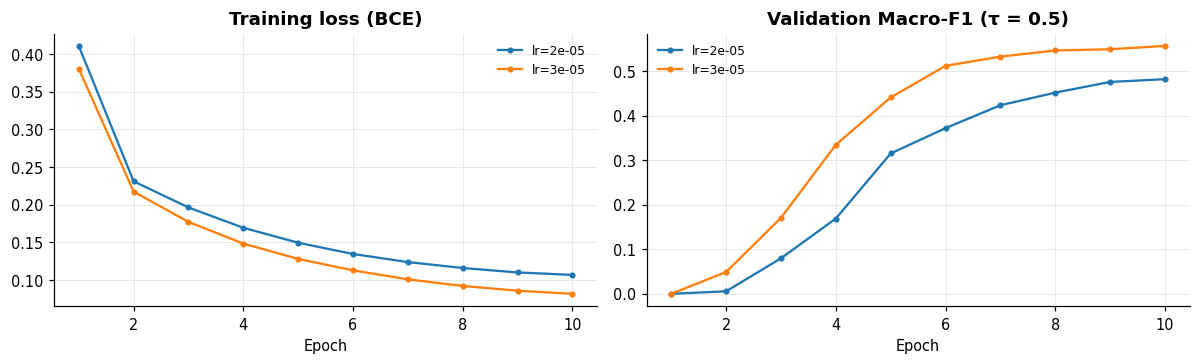

In [22]:
def build_phobert_data():
    data = {}
    for s in SPLITS:
        enc = tokenizer(list(dfs[s]['text_seg']), truncation=True, max_length=PHOBERT_MAX_LEN)
        data[s] = [(enc['input_ids'][i], Y[s][i].astype(np.float32)) for i in range(len(dfs[s]))]
    return data


def collate_phobert(batch):
    enc = tokenizer.pad([{'input_ids': ids} for ids, _ in batch], return_tensors='pt')
    return {'input_ids': enc['input_ids'], 'attention_mask': enc['attention_mask'],
            'labels': torch.tensor(np.stack([y for _, y in batch]))}


def phobert_forward(model, batch):
    return model(input_ids=batch['input_ids'].to(DEVICE), attention_mask=batch['attention_mask'].to(DEVICE)).logits


def new_phobert():
    return AutoModelForSequenceClassification.from_pretrained(
        PHOBERT_NAME, num_labels=N_LABELS, problem_type='multi_label_classification').to(DEVICE)


def train_phobert(run_dir):
    c = CFG['phobert']
    data = build_phobert_data()
    loaders = {s: make_loader(ListDataset(data[s]), c['batch_size'], s == 'train', collate_phobert) for s in SPLITS}
    grid, history, best, t_search = [], [], None, time.time()
    for lr in c['lr_grid']:
        seed_everything()
        model = new_phobert()
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=c['weight_decay'])
        total_steps = c['max_epochs'] * len(loaders['train'])
        scheduler = get_linear_schedule_with_warmup(optimizer, int(c['warmup_ratio'] * total_steps), total_steps)
        r = train_torch(model, loaders['train'], loaders['val'], phobert_forward, optimizer, scheduler,
                        c['max_epochs'], c['patience'], c['grad_clip'], f'lr={lr}', amp=USE_AMP)
        grid.append({'lr': lr, 'best_epoch': r['best_epoch'], 'val_macro_f1': r['best_val_macro_f1'],
                     'train_time_s': r['train_time_s']})
        history += r['history']
        if best is None or r['best_val_macro_f1'] > best['f1']:
            best = {'f1': r['best_val_macro_f1'], 'lr': lr, 'epoch': r['best_epoch'], 'time': r['train_time_s'],
                    'state': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
        del model, optimizer, scheduler
        if USE_AMP:
            torch.cuda.empty_cache()

    model = new_phobert()
    model.load_state_dict(best.pop('state'))
    model.save_pretrained(run_dir / 'model_best'); tokenizer.save_pretrained(run_dir / 'model_best')
    return {'selected': {'lr': best['lr'], 'best_epoch': best['epoch'], 'max_len': PHOBERT_MAX_LEN, 'checkpoint': PHOBERT_NAME},
            'selected_val_macro_f1': best['f1'], 'grid': grid, 'history': history,
            'n_params': sum(p.numel() for p in model.parameters()),
            'train_time_s': best['time'], 'search_time_s': time.time() - t_search,
            'probs_val': predict_probs(model, loaders['val'], phobert_forward, USE_AMP),
            'probs_test': predict_probs(model, loaders['test'], phobert_forward, USE_AMP)}


results['phobert'] = run_or_load('phobert', {**CFG['phobert'], 'max_len': PHOBERT_MAX_LEN}, train_phobert)
show_selection(results['phobert'])

## 5. Part C — Required Metrics

All metrics at τ = 0.5 over all 28 labels. Macro-F1 = mean of the 28 per-label F1 (every label counts equally);
Micro-F1 = F1 over all label decisions pooled (frequent labels weigh more); Hamming loss = share of wrong label decisions;
LRAP and mAP are threshold-free ranking metrics computed from the probabilities.

In [23]:
MODELS = ['tfidf_lr', 'bilstm', 'phobert']
NAMES = {'tfidf_lr': 'TF-IDF + OvR LR', 'bilstm': 'BiLSTM', 'phobert': 'PhoBERT'}
P_VAL = {m: results[m]['probs_val'] for m in MODELS}
P_TEST = {m: results[m]['probs_test'] for m in MODELS}
PRED_TEST = {m: (P_TEST[m] >= THR).astype(int) for m in MODELS}

rows = []
for m in MODELS:
    for split, y, p in [('val', Y_val, P_VAL[m]), ('test', Y_test, P_TEST[m])]:
        rows.append({'model': NAMES[m], 'split': split, **compute_metrics(y, p),
                     'params': results[m]['n_params'], 'train_time_min': results[m]['train_time_s'] / 60})
main_table = pd.DataFrame(rows)
print('Main results (τ = 0.5). Selection used validation only; test evaluated once.')
display(main_table.style.format({'macro_f1': '{:.4f}', 'micro_f1': '{:.4f}', 'hamming_loss': '{:.4f}', 'lrap': '{:.4f}',
                                 'mAP': '{:.4f}', 'params': '{:,}', 'train_time_min': '{:.1f}'}).hide(axis='index'))

Main results (τ = 0.5). Selection used validation only; test evaluated once.


model,split,macro_f1,micro_f1,hamming_loss,lrap,mAP,params,train_time_min
TF-IDF + OvR LR,val,0.5298,0.5475,0.0675,0.6788,0.5478,"2,370,340",0.6
TF-IDF + OvR LR,test,0.5365,0.5546,0.0663,0.6876,0.5559,"2,370,340",0.6
BiLSTM,val,0.4934,0.5212,0.0612,0.6479,0.5032,"4,931,608",2.2
BiLSTM,test,0.4892,0.5156,0.0618,0.6491,0.5072,"4,931,608",2.2
PhoBERT,val,0.5563,0.5922,0.0497,0.7324,0.6032,"135,019,804",13.7
PhoBERT,test,0.5671,0.6051,0.0481,0.7445,0.6136,"135,019,804",13.7


Per-label F1 on test (τ = 0.5), sorted by train frequency


,train_count,tier,TF-IDF + OvR LR,BiLSTM,PhoBERT
amusement,2868,head,0.733,0.692,0.760
sadness,2785,head,0.677,0.654,0.748
annoyance,2662,head,0.534,0.469,0.559
joy,1614,head,0.543,0.461,0.566
anger,1589,head,0.542,0.494,0.571
disappointment,1522,head,0.390,0.354,0.458
disgust,1206,head,0.435,0.368,0.395
love,1175,head,0.650,0.594,0.688
caring,1062,head,0.571,0.498,0.639
optimism,1046,mid,0.631,0.601,0.679


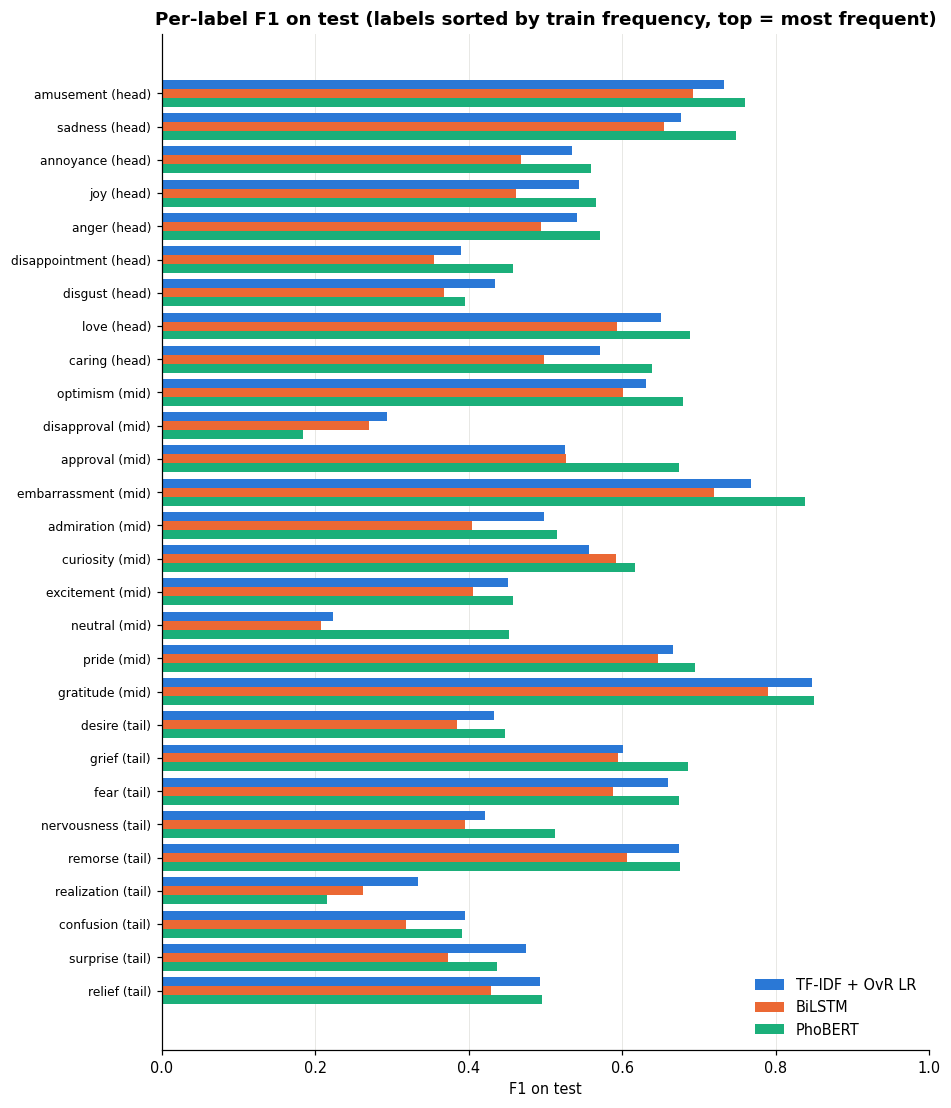

Mean per-label F1 by tier (test)


,TF-IDF + OvR LR,BiLSTM,PhoBERT
head,0.564,0.509,0.598
mid,0.546,0.516,0.596
tail,0.499,0.439,0.504


In [24]:
per_label = pd.DataFrame({NAMES[m]: f1_score(Y_test, PRED_TEST[m], average=None, zero_division=0) for m in MODELS},
                         index=LABELS)
per_label.insert(0, 'train_count', Y_train.sum(0))
per_label.insert(1, 'tier', [TIER_OF[l] for l in LABELS])
per_label = per_label.sort_values('train_count', ascending=False)
print('Per-label F1 on test (τ = 0.5), sorted by train frequency')
display(per_label.round(3))

fig, ax = plt.subplots(figsize=(9, 12))
yy = np.arange(N_LABELS)[::-1]; h = 0.27
for k, m in enumerate(MODELS):
    ax.barh(yy + (1 - k) * h, per_label[NAMES[m]], height=h, color=MODEL_COLORS[m], label=NAMES[m])
ax.set_yticks(yy); ax.set_yticklabels([f'{l} ({TIER_OF[l]})' for l in per_label.index], fontsize=8)
ax.set_xlabel('F1 on test'); ax.set_xlim(0, 1)
ax.set_title('Per-label F1 on test (labels sorted by train frequency, top = most frequent)')
ax.legend(frameon=False, loc='lower right'); ax.grid(axis='y', visible=False)
plt.show()

tier_f1 = pd.DataFrame({NAMES[m]: {t: per_label.loc[per_label['tier'] == t, NAMES[m]].mean() for t in TIERS} for m in MODELS})
print('Mean per-label F1 by tier (test)'); display(tier_f1.round(3))

### 5.1 Saved outputs

One prediction file per model and split in `results/predictions/` (`sample_id`, gold vector, probability vector,
prediction at τ = 0.5; vectors are JSON lists in label-index order), plus the main and per-label tables in
`results/tables/`. No comment text is written. The prediction files pair comment ids with gold labels, so they stay out of the public GitHub repository (see `.gitignore`).

In [25]:
# Per-comment predictions of every reported model (required by the submission guide) and the two result tables.
# Probabilities are written at full precision so 02_Final_RQ1_Threshold_Decoding.ipynb can reuse them exactly.
PRED_DIR, TABLE_DIR = RESULTS_DIR / 'predictions', RESULTS_DIR / 'tables'
PRED_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def as_json(rows):
    return [json.dumps(r) for r in rows.tolist()]


for m in MODELS:
    for split, y, p in [('val', Y_val, P_VAL[m]), ('test', Y_test, P_TEST[m])]:
        pd.DataFrame({'sample_id': dfs[split]['id'], 'true_label_vector': as_json(y.astype(int)),
                      'probability_vector': as_json(p.astype(float)),
                      'pred_fixed': as_json((p >= THR).astype(int))}
                     ).to_csv(PRED_DIR / f'midterm_{m}_{split}.csv', index=False)
main_table.to_csv(TABLE_DIR / 'midterm_main_metrics.csv', index=False)
per_label.to_csv(TABLE_DIR / 'midterm_per_label_f1.csv')
print('Saved', ', '.join(f'midterm_{m}_{{val,test}}.csv' for m in MODELS), 'to results/predictions/')
print('Saved midterm_main_metrics.csv, midterm_per_label_f1.csv to results/tables/')

Saved midterm_tfidf_lr_{val,test}.csv, midterm_bilstm_{val,test}.csv, midterm_phobert_{val,test}.csv to results/predictions/
Saved midterm_main_metrics.csv, midterm_per_label_f1.csv to results/tables/


## 6. Part D — Midterm Questions

Q1–Q4 analyse the **test** predictions of the already-selected models (no further selection happens).
Q5 changes the decision threshold, so it is done on **validation** only, keeping the test set untouched for the Final.

### Q1. Which emotion labels have the highest and lowest F1?

In [26]:
for m in MODELS:
    s = per_label[NAMES[m]].sort_values(ascending=False)
    print(f'{NAMES[m]:<16s} highest: ' + ', '.join(f'{l} ({v:.3f})' for l, v in s.head(3).items()))
    print(f'{"":<16s} lowest : ' + ', '.join(f'{l} ({v:.3f})' for l, v in s.tail(3)[::-1].items()))

rank = per_label[[NAMES[m] for m in MODELS]].rank(ascending=False)
consistent_low = [l for l in LABELS if (rank.loc[l] >= N_LABELS - 4).all()]
consistent_high = [l for l in LABELS if (rank.loc[l] <= 5).all()]
print('\nIn the top-5 for all three models   :', consistent_high or 'none')
print('In the bottom-5 for all three models:', consistent_low or 'none')

TF-IDF + OvR LR  highest: gratitude (0.847), embarrassment (0.768), amusement (0.733)
                 lowest : neutral (0.223), disapproval (0.293), realization (0.333)
BiLSTM           highest: gratitude (0.790), embarrassment (0.720), amusement (0.692)
                 lowest : neutral (0.208), realization (0.262), disapproval (0.270)
PhoBERT          highest: gratitude (0.850), embarrassment (0.838), amusement (0.760)
                 lowest : disapproval (0.184), realization (0.215), confusion (0.391)

In the top-5 for all three models   : ['amusement', 'gratitude', 'embarrassment', 'sadness']
In the bottom-5 for all three models: ['realization', 'confusion', 'disapproval']


### Q2. How strongly does per-label F1 correlate with training label frequency?

Spearman correlation between train count and test F1 across the 28 labels


,spearman_rho,p_value
TF-IDF + OvR LR,0.2414,0.2159
BiLSTM,0.2414,0.2159
PhoBERT,0.2950,0.1275


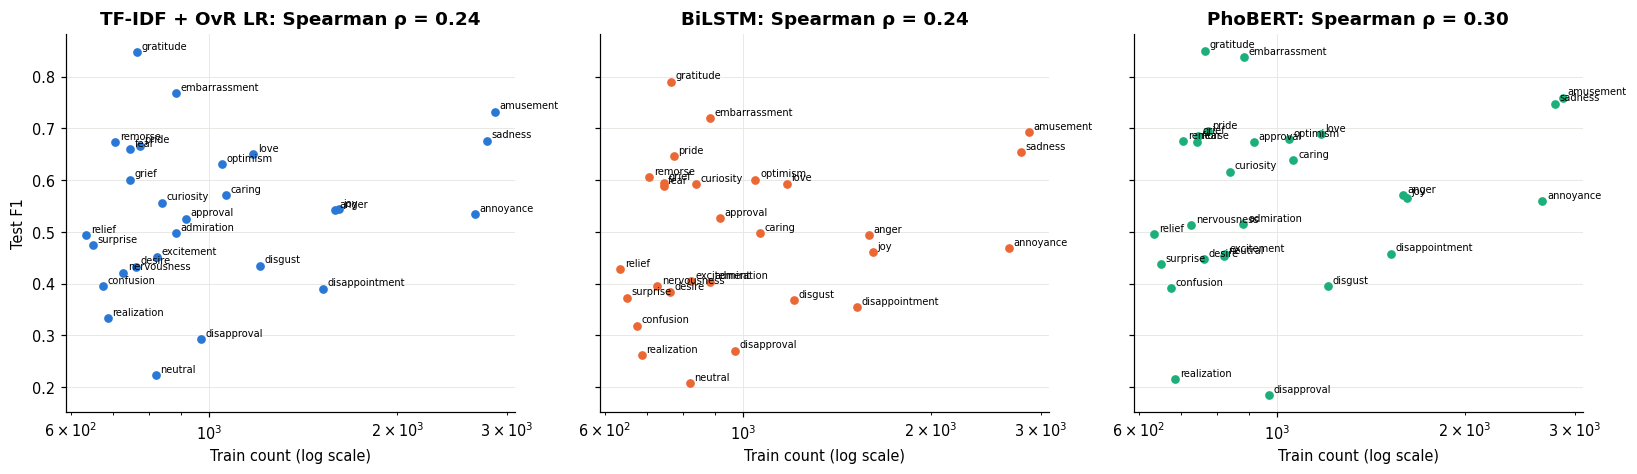

In [27]:
freq = per_label['train_count']
corr = pd.DataFrame({NAMES[m]: dict(zip(['spearman_rho', 'p_value'], spearmanr(freq, per_label[NAMES[m]]))) for m in MODELS}).T
print('Spearman correlation between train count and test F1 across the 28 labels')
display(corr.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, m in zip(axes, MODELS):
    ax.scatter(freq, per_label[NAMES[m]], s=22, color=MODEL_COLORS[m])
    for l in per_label.index:
        ax.annotate(l, (freq[l], per_label.loc[l, NAMES[m]]), fontsize=6.5, xytext=(3, 2), textcoords='offset points')
    ax.set_xscale('log'); ax.set_xlabel('Train count (log scale)')
    ax.set_title(f"{NAMES[m]}: Spearman ρ = {corr.loc[NAMES[m], 'spearman_rho']:.2f}")
axes[0].set_ylabel('Test F1')
fig.tight_layout(); plt.show()

### Q3. Which emotion pairs co-occur most, and do the baselines preserve these dependencies?

For the 10 pairs that co-occur most in the **test gold labels**: how often each model predicts the pair together,
and *pair recall* = share of gold co-occurrences where the model predicts both labels.
Pearson r between gold and predicted co-occurrence counts over all 378 label pairs measures how well the overall
dependency structure is reproduced.

In [28]:
iu = np.triu_indices(N_LABELS, 1)
gold_cooc = (Y_test.T.astype(int) @ Y_test.astype(int))
pair_rows = []
order_pairs = np.argsort(-gold_cooc[iu])[:10]
for k in order_pairs:
    i, j = iu[0][k], iu[1][k]
    row = {'pair': f'{LABELS[i]} + {LABELS[j]}', 'gold_count': int(gold_cooc[i, j])}
    both_gold = (Y_test[:, i] == 1) & (Y_test[:, j] == 1)
    for m in MODELS:
        P = PRED_TEST[m]
        row[f'{NAMES[m]} predicted'] = int(((P[:, i] == 1) & (P[:, j] == 1)).sum())
        row[f'{NAMES[m]} pair recall'] = ((P[both_gold, i] == 1) & (P[both_gold, j] == 1)).mean()
    pair_rows.append(row)
display(pd.DataFrame(pair_rows).round(3))

structure = {}
for m in MODELS:
    pred_cooc = PRED_TEST[m].T @ PRED_TEST[m]
    r, _ = pearsonr(gold_cooc[iu], pred_cooc[iu])
    gold_top = set(np.argsort(-gold_cooc[iu])[:15]); pred_top = set(np.argsort(-pred_cooc[iu])[:15])
    structure[NAMES[m]] = {'pearson_r_all_pairs': r, 'overlap_of_top15_pairs': len(gold_top & pred_top)}
print('Overall dependency structure (test)')
display(pd.DataFrame(structure).T.round(3))

,pair,gold_count,TF-IDF + OvR LR predicted,TF-IDF + OvR LR pair recall,BiLSTM predicted,BiLSTM pair recall,PhoBERT predicted,PhoBERT pair recall
0,disappointment + sadness,127,128,0.402,118,0.409,127,0.496
1,anger + annoyance,84,159,0.476,93,0.298,59,0.179
2,sadness + grief,71,106,0.690,98,0.690,91,0.718
3,amusement + joy,70,119,0.500,77,0.300,81,0.514
4,annoyance + disapproval,59,96,0.288,54,0.169,25,0.186
5,amusement + excitement,50,49,0.400,23,0.180,32,0.320
6,optimism + caring,50,62,0.520,39,0.340,47,0.400
7,remorse + sadness,47,52,0.532,46,0.532,39,0.404
8,excitement + joy,46,63,0.391,29,0.261,41,0.391
9,fear + nervousness,43,57,0.581,43,0.465,42,0.512


Overall dependency structure (test)


,pearson_r_all_pairs,overlap_of_top15_pairs
TF-IDF + OvR LR,0.934,13.0
BiLSTM,0.956,12.0
PhoBERT,0.940,12.0


### Q4. On which text styles does PhoBERT outperform the recurrent baseline most?

Slices of the test set, defined on the **raw** text with cut-offs taken from train:
`short` = whitespace tokens ≤ train 25th percentile; `emoji-heavy` = ≥ 2 emoji; `teencode` = ≥ 1 lexicon hit (Section 2.7).
Macro-F1 inside a slice averages only labels that occur in the slice. Δ = PhoBERT − BiLSTM with a paired bootstrap
95 % confidence interval (1,000 resamples).

In [29]:
short_cut = np.percentile(dfs['train']['n_tokens'], 25)
ftest = feats['test']
slices = {'all test': np.ones(len(Y_test), bool),
          f'short (<= {short_cut:.0f} tokens)': (dfs['test']['n_tokens'] <= short_cut).to_numpy(),
          'emoji-heavy (>= 2 emoji)': (ftest['n_emoji'] >= 2).to_numpy(),
          'teencode': ftest['has_teencode'].to_numpy()}


def slice_f1(y, p):
    present = np.flatnonzero(y.sum(0) > 0)
    return (f1_score(y, p, average='micro', zero_division=0),
            f1_score(y[:, present], p[:, present], average='macro', zero_division=0))


rng_boot = np.random.default_rng(SEED)
rows = []
for name, mask in slices.items():
    idx = np.flatnonzero(mask)
    yb, pb, pp = Y_test[idx], PRED_TEST['bilstm'][idx], PRED_TEST['phobert'][idx]
    mi_b, ma_b = slice_f1(yb, pb); mi_p, ma_p = slice_f1(yb, pp)
    d_mi, d_ma = [], []
    for _ in range(CFG['bootstrap']):
        s = rng_boot.integers(0, len(idx), len(idx))
        a, b = slice_f1(yb[s], pp[s]), slice_f1(yb[s], pb[s])
        d_mi.append(a[0] - b[0]); d_ma.append(a[1] - b[1])
    rows.append({'slice': name, 'n': len(idx),
                 'BiLSTM micro': mi_b, 'PhoBERT micro': mi_p, 'Δ micro': mi_p - mi_b,
                 'Δ micro 95% CI': f'[{np.percentile(d_mi, 2.5):+.3f}, {np.percentile(d_mi, 97.5):+.3f}]',
                 'BiLSTM macro': ma_b, 'PhoBERT macro': ma_p, 'Δ macro': ma_p - ma_b,
                 'Δ macro 95% CI': f'[{np.percentile(d_ma, 2.5):+.3f}, {np.percentile(d_ma, 97.5):+.3f}]'})
q4 = pd.DataFrame(rows)
display(q4.round(3))
styles = q4[q4['slice'] != 'all test']
print(f"Largest PhoBERT gain (Micro-F1): {styles.loc[styles['Δ micro'].idxmax(), 'slice']}"
      f" | (Macro-F1): {styles.loc[styles['Δ macro'].idxmax(), 'slice']}")

,slice,n,BiLSTM micro,PhoBERT micro,Δ micro,Δ micro 95% CI,BiLSTM macro,PhoBERT macro,Δ macro,Δ macro 95% CI
0,all test,2067,0.516,0.605,0.090,"[+0.074, +0.104]",0.489,0.567,0.078,"[+0.061, +0.094]"
1,short (<= 7 tokens),595,0.581,0.665,0.084,"[+0.058, +0.110]",0.524,0.612,0.088,"[+0.055, +0.119]"
2,emoji-heavy (>= 2 emoji),180,0.639,0.667,0.028,"[-0.015, +0.071]",0.539,0.535,-0.004,"[-0.074, +0.066]"
3,teencode,341,0.460,0.559,0.099,"[+0.064, +0.134]",0.422,0.519,0.097,"[+0.053, +0.139]"


Largest PhoBERT gain (Micro-F1): teencode | (Macro-F1): teencode


### Q5. How sensitive are the baselines to the default threshold τ = 0.5? (validation only)

The same τ is applied to every label and swept from 0.05 to 0.95. This is exploratory; choosing thresholds formally is the
Final research question (RQ1), so nothing selected here is applied to the test set.

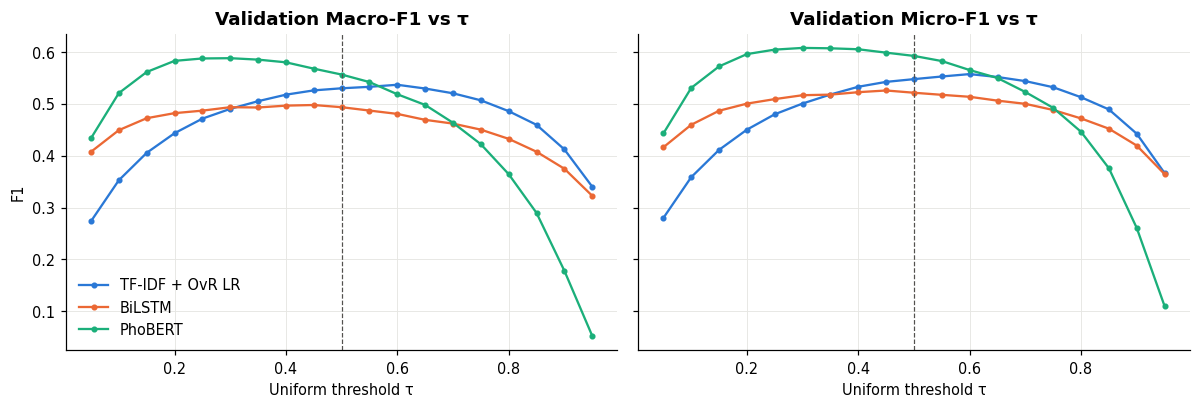

,model,macro_f1@0.5,best τ (macro),macro_f1@best,Δ macro,macro range over τ,labels never predicted @0.5,mean predicted labels @0.5,mean gold labels,% comments with no label @0.5
0,TF-IDF + OvR LR,0.530,0.60,0.537,0.007,0.263,0,2.261,1.916,5.712
1,BiLSTM,0.493,0.45,0.498,0.004,0.175,0,1.663,1.916,9.390
2,PhoBERT,0.556,0.30,0.588,0.032,0.535,0,1.494,1.916,6.099


In [30]:
taus = np.round(np.arange(0.05, 0.951, 0.05), 2)
sweep = {m: pd.DataFrame([{'tau': t, **{k: v for k, v in compute_metrics(Y_val, P_VAL[m], t).items()
                                        if k in ('macro_f1', 'micro_f1')}} for t in taus]) for m in MODELS}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ['macro_f1', 'micro_f1']):
    for m in MODELS:
        ax.plot(sweep[m]['tau'], sweep[m][metric], marker='o', ms=3, color=MODEL_COLORS[m], label=NAMES[m])
    ax.axvline(0.5, color='#52514e', lw=0.8, ls='--')
    ax.set_xlabel('Uniform threshold τ'); ax.set_title(f'Validation {metric.replace("_", "-").title()} vs τ')
axes[0].set_ylabel('F1'); axes[0].legend(frameon=False)
fig.tight_layout(); plt.show()

rows = []
for m in MODELS:
    sw = sweep[m]; at05 = sw.loc[sw['tau'] == 0.5].iloc[0]; best = sw.loc[sw['macro_f1'].idxmax()]
    P05 = (P_VAL[m] >= 0.5).astype(int)
    rows.append({'model': NAMES[m], 'macro_f1@0.5': at05['macro_f1'], 'best τ (macro)': best['tau'],
                 'macro_f1@best': best['macro_f1'], 'Δ macro': best['macro_f1'] - at05['macro_f1'],
                 'macro range over τ': sw['macro_f1'].max() - sw['macro_f1'].min(),
                 'labels never predicted @0.5': int((P05.sum(0) == 0).sum()),
                 'mean predicted labels @0.5': P05.sum(1).mean(), 'mean gold labels': Y_val.sum(1).mean(),
                 '% comments with no label @0.5': 100 * (P05.sum(1) == 0).mean()})
q5 = pd.DataFrame(rows)
display(q5.round(3))

## 7. Error Analysis (best neural model, test set, τ = 0.5)

The neural model with the highest **validation** Macro-F1 is analysed (this is also the model RQ1 will use).

Analysed model: PhoBERT (val Macro-F1 = 0.5563)
7.1 Performance by number of gold labels


,|Y|,n,% same #labels,% fewer,% more,% exact set match,micro_f1,macro_f1 (present labels),mean predicted labels
0,1,695,65.755,8.633,25.612,49.496,0.595,0.513,1.216
1,2,946,43.763,47.780,8.457,21.882,0.601,0.559,1.538
2,3,360,18.333,79.167,2.500,9.722,0.633,0.561,1.856
3,>=4,66,4.545,95.455,0.000,1.515,0.564,0.439,2.121


Comments with no predicted label: 144 (7.0%)


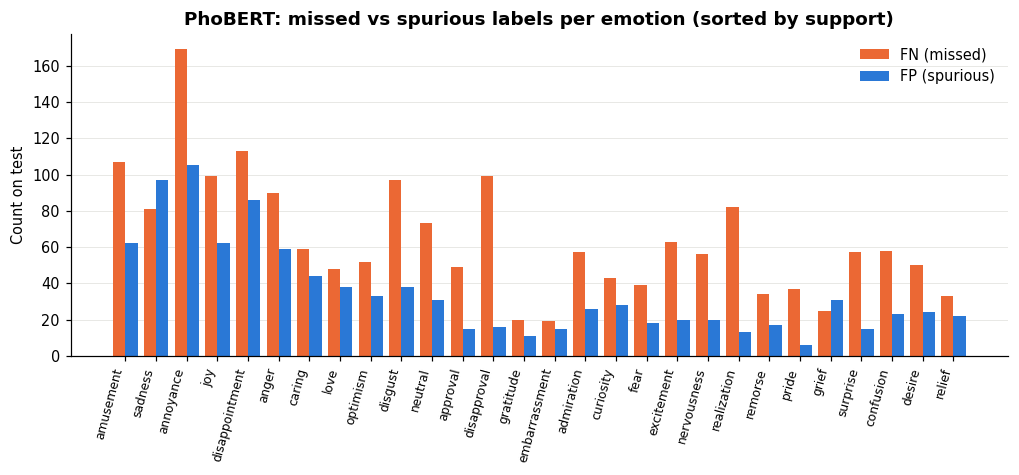

7.3 Most frequent confusions (gold label missed -> wrong label predicted in the same comment)


,gold (missed),predicted instead,count
0,annoyance,sadness,21
1,disgust,annoyance,20
2,anger,annoyance,20
3,disapproval,anger,18
4,annoyance,anger,17
5,disapproval,annoyance,15
6,annoyance,disgust,14
7,annoyance,disappointment,14
8,amusement,annoyance,12
9,disgust,anger,12


In [31]:
BEST = max(['bilstm', 'phobert'], key=lambda m: results[m]['selected_val_macro_f1'])
P = PRED_TEST[BEST]; YT = Y_test
print(f'Analysed model: {NAMES[BEST]} (val Macro-F1 = {results[BEST]["selected_val_macro_f1"]:.4f})')

# 7.1 Performance by label cardinality (layout of Table 6 in the ViGoEmotions paper)
card = YT.sum(1); n_pred = P.sum(1)
rows = []
for b in ['1', '2', '3', '>=4']:
    idx = np.flatnonzero(np.array([bucket(n) for n in card]) == b)
    mi, ma = slice_f1(YT[idx], P[idx])
    rows.append({'|Y|': b, 'n': len(idx), '% same #labels': 100 * (n_pred[idx] == card[idx]).mean(),
                 '% fewer': 100 * (n_pred[idx] < card[idx]).mean(), '% more': 100 * (n_pred[idx] > card[idx]).mean(),
                 '% exact set match': 100 * (P[idx] == YT[idx]).all(1).mean(),
                 'micro_f1': mi, 'macro_f1 (present labels)': ma, 'mean predicted labels': n_pred[idx].mean()})
print('7.1 Performance by number of gold labels'); display(pd.DataFrame(rows).round(3))
print(f'Comments with no predicted label: {(n_pred == 0).sum()} ({100 * (n_pred == 0).mean():.1f}%)')

# 7.2 False negatives / false positives per label
fn = ((YT == 1) & (P == 0)).sum(0); fp = ((YT == 0) & (P == 1)).sum(0)
err = pd.DataFrame({'FN (missed)': fn, 'FP (spurious)': fp, 'support': YT.sum(0)}, index=LABELS).sort_values('support', ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(N_LABELS)
ax.bar(x - 0.2, err['FN (missed)'], 0.4, color='#eb6834', label='FN (missed)')
ax.bar(x + 0.2, err['FP (spurious)'], 0.4, color='#2a78d6', label='FP (spurious)')
ax.set_xticks(x); ax.set_xticklabels(err.index, rotation=75, ha='right', fontsize=8)
ax.set_ylabel('Count on test'); ax.set_title(f'{NAMES[BEST]}: missed vs spurious labels per emotion (sorted by support)')
ax.legend(frameon=False); ax.grid(axis='x', visible=False)
plt.show()

# 7.3 Confused pairs: gold label a missed while label b was predicted wrongly in the same comment
conf = Counter()
for i in range(len(YT)):
    for a in np.flatnonzero((YT[i] == 1) & (P[i] == 0)):
        for b in np.flatnonzero((YT[i] == 0) & (P[i] == 1)):
            conf[(LABELS[a], LABELS[b])] += 1
print('7.3 Most frequent confusions (gold label missed -> wrong label predicted in the same comment)')
display(pd.DataFrame([{'gold (missed)': a, 'predicted instead': b, 'count': n} for (a, b), n in conf.most_common(15)]))

### 7.4 Edge cases

Comments with the most wrong label decisions, emoji-only comments, very short comments, and comments with |Y| ≥ 4.

In [32]:
PROB = P_TEST[BEST]


def show_case(i):
    gold = [LABELS[j] for j in np.flatnonzero(YT[i])]
    pred = [LABELS[j] for j in np.flatnonzero(P[i])]
    top = ', '.join(f'{LABELS[j]}={PROB[i, j]:.2f}' for j in np.argsort(-PROB[i])[:3])
    print(f"  {comment_text(dfs['test'], i)}\n     gold={gold}  pred={pred}  top-3: {top}")


n_err = (P != YT).sum(1)
groups = {'most wrong label decisions': np.argsort(-n_err)[:5],
          'emoji-only comments with an error': [i for i in np.flatnonzero(ftest['emoji_only'].to_numpy()) if n_err[i] > 0][:5],
          'very short comments (<= 2 tokens) with an error': [i for i in np.flatnonzero((dfs['test']['n_tokens'] <= 2).to_numpy()) if n_err[i] > 0][:5],
          '|Y| >= 4': np.flatnonzero(card >= 4)[:5]}
for title, idx in groups.items():
    print(f'--- {title} ---')
    for i in idx:
        show_case(i)
    print()

--- most wrong label decisions ---
  [comment id 25688]
     gold=['surprise', 'curiosity', 'confusion']  pred=['amusement', 'annoyance', 'disapproval']  top-3: amusement=0.97, annoyance=0.82, disapproval=0.52
  [comment id 16719]
     gold=['amusement', 'fear', 'grief', 'disgust']  pred=['annoyance']  top-3: annoyance=0.80, disgust=0.43, anger=0.39
  [comment id 3832]
     gold=['desire', 'caring', 'realization', 'sadness']  pred=['love', 'caring', 'gratitude']  top-3: love=0.86, caring=0.68, gratitude=0.64
  [comment id tik004830]
     gold=['caring']  pred=['joy', 'optimism', 'gratitude', 'relief']  top-3: relief=0.71, gratitude=0.69, optimism=0.59
  [comment id 6293]
     gold=['love', 'desire', 'fear', 'nervousness']  pred=['fear', 'sadness', 'grief']  top-3: sadness=0.97, fear=0.57, grief=0.53

--- emoji-only comments with an error ---
  [comment id 16632]
     gold=['joy', 'love']  pred=['love']  top-3: love=0.78, joy=0.40, desire=0.36
  [comment id tik020108]
     gold=['embarr

### 7.5 Confusion matrices

ViGoEmotions is **multi-label**, so there is no single standard N×N confusion matrix. Three views are used
(all on **test**, τ = 0.5, same model as above):

1. **Per-label 2×2 matrix** (`multilabel_confusion_matrix`): TP / FP / FN / TN of every emotion treated as its own yes/no task.
   These are the counts behind each per-label F1.
2. **Gold × predicted label matrix (28 × 28 + `none`)**. Row = gold emotion *a*, column = predicted emotion *b*, counted over
   the test comments that carry *a*:
   * diagonal (*a*, *a*): *a* was predicted (= recall of *a*);
   * off-diagonal (*a*, *b*): *b* was predicted although *b* is **not** a gold label of that comment (a wrong label given to *a*'s comments);
   * column `none`: the model predicted no label at all for the comment.

   Rows are divided by the support of *a*, so a row reads "of the comments whose gold label is *a*, x % received *b*".
   Correct extra labels (another gold label of the same comment) are not counted off the diagonal, so every off-diagonal
   cell is an error. Unlike 7.3, *a* does not have to be missed: the matrix also shows wrong labels added next to a correct one.
3. **Sentiment-group matrix (4 × 4)**: the same counts summed over the groups positive / ambiguous / negative / neutral,
   to see whether errors stay inside the right sentiment or cross to the opposite one.

7.5.1 Per-label confusion counts on test (PhoBERT, τ = 0.5), sorted by support


,tier,support,TP,FN,FP,TN,precision,recall,F1
amusement,head,374,267,107,62,1631,0.812,0.714,0.760
sadness,head,345,264,81,97,1625,0.731,0.765,0.748
annoyance,head,343,174,169,105,1619,0.624,0.507,0.559
joy,head,204,105,99,62,1801,0.629,0.515,0.566
disappointment,head,197,84,113,86,1784,0.494,0.426,0.458
anger,head,189,99,90,59,1819,0.627,0.524,0.571
caring,head,150,91,59,44,1873,0.674,0.607,0.639
love,head,143,95,48,38,1886,0.714,0.664,0.688
optimism,mid,142,90,52,33,1892,0.732,0.634,0.679
disgust,head,141,44,97,38,1888,0.537,0.312,0.395


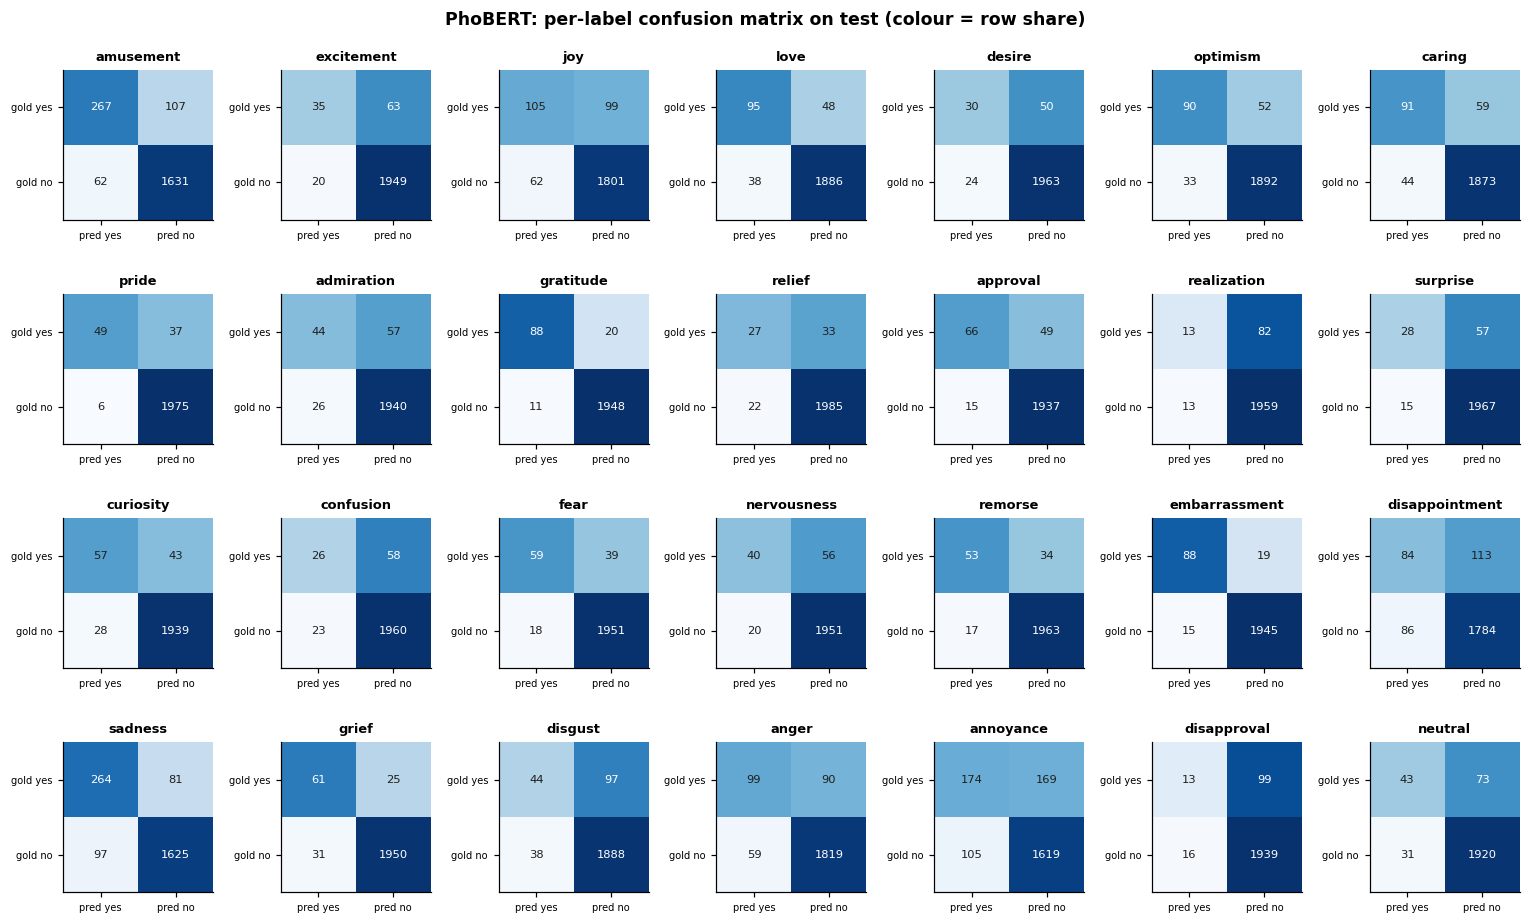

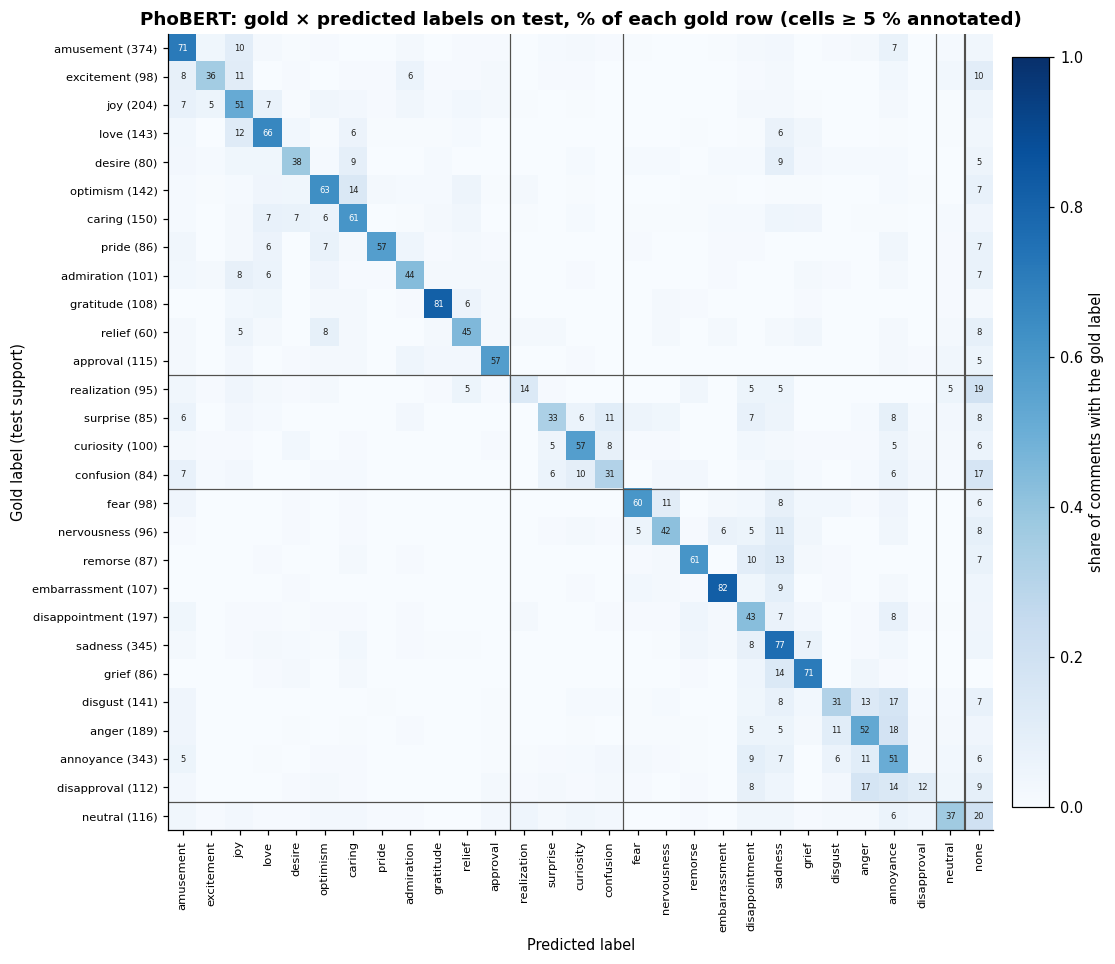

7.5.2 Most frequent wrong labels per gold emotion (gold support >= 20), by % of the gold row


,gold label,wrongly predicted,count,% of gold row,gold support,crosses sentiment group
0,neutral,none,23,19.8,116,False
1,realization,none,18,18.9,95,False
2,anger,annoyance,34,18.0,189,False
3,disgust,annoyance,24,17.0,141,False
4,disapproval,anger,19,17.0,112,False
5,confusion,none,14,16.7,84,False
6,disapproval,annoyance,16,14.3,112,False
7,optimism,caring,20,14.1,142,False
8,grief,sadness,12,14.0,86,False
9,disgust,anger,19,13.5,141,False


Wrong label most often given to each emotion:


,wrongly predicted,count,% of gold row,gold support,crosses sentiment group
gold label,,,,,
amusement,joy,38,10.2,374,False
excitement,joy,11,11.2,98,False
joy,amusement,15,7.4,204,False
love,joy,17,11.9,143,False
desire,caring,7,8.8,80,False
optimism,caring,20,14.1,142,False
caring,love,11,7.3,150,False
pride,optimism,6,7.0,86,False
admiration,joy,8,7.9,101,False


7.5.3 Sentiment-group matrix: counts (diagonal block = correct label or a wrong label of the same group)


,pred positive,pred ambiguous,pred negative,pred neutral,pred none
gold positive,1437,31,164,20,84
gold ambiguous,50,165,73,10,45
gold negative,142,43,1598,21,98
gold neutral,21,14,26,43,23


Row share (%)


,pred positive,pred ambiguous,pred negative,pred neutral,pred none
gold positive,82.8,1.8,9.4,1.2,4.8
gold ambiguous,14.6,48.1,21.3,2.9,13.1
gold negative,7.5,2.3,84.0,1.1,5.2
gold neutral,16.5,11.0,20.5,33.9,18.1


In [33]:
# 7.5.1 Per-label 2x2 confusion matrices (TP / FP / FN / TN)
mcm = multilabel_confusion_matrix(YT, P)          # shape (28, 2, 2): [[TN, FP], [FN, TP]]
cm_table = pd.DataFrame({'support': YT.sum(0), 'TP': mcm[:, 1, 1], 'FN': mcm[:, 1, 0],
                         'FP': mcm[:, 0, 1], 'TN': mcm[:, 0, 0]}, index=LABELS)
cm_table['precision'] = cm_table['TP'] / (cm_table['TP'] + cm_table['FP']).replace(0, np.nan)
cm_table['recall'] = cm_table['TP'] / cm_table['support'].replace(0, np.nan)
cm_table['F1'] = f1_score(YT, P, average=None, zero_division=0)
cm_table.insert(0, 'tier', [TIER_OF[l] for l in LABELS])
print(f'7.5.1 Per-label confusion counts on test ({NAMES[BEST]}, τ = {THR}), sorted by support')
display(cm_table.sort_values('support', ascending=False).round(3))

fig, axes = plt.subplots(4, 7, figsize=(14, 8.6))
for ax, c in zip(axes.ravel(), range(N_LABELS)):
    m = mcm[c][::-1, ::-1]                         # [[TP, FN], [FP, TN]]: positive class first
    ax.imshow(m / m.sum(1, keepdims=True).clip(min=1), cmap='Blues', vmin=0, vmax=1)
    for (r, k), v in np.ndenumerate(m):
        ax.text(k, r, f'{v}', ha='center', va='center', fontsize=7.5,
                color='white' if v / max(m[r].sum(), 1) > 0.6 else '#1f1f1d')
    ax.set_title(LABELS[c], fontsize=8.5); ax.grid(False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['pred yes', 'pred no'], fontsize=6.5)
    ax.set_yticks([0, 1]); ax.set_yticklabels(['gold yes', 'gold no'], fontsize=6.5)
fig.suptitle(f'{NAMES[BEST]}: per-label confusion matrix on test (colour = row share)', fontweight='semibold')
plt.tight_layout(); plt.show()


# 7.5.2 Gold x predicted label matrix
def label_confusion(y, pred):
    # Row a = comments with gold label a. Cell (a, a) = a predicted; cell (a, b) = b predicted but not gold;
    # last column = no label predicted. Returns counts with shape (N_LABELS, N_LABELS + 1).
    y, pred = y.astype(int), pred.astype(int)
    wrong = pred * (1 - y)                                    # predicted labels that are not gold
    m = y.T @ wrong                                           # (a, b): gold a, wrong prediction b
    m[np.diag_indices(N_LABELS)] = (y * pred).sum(0)          # diagonal: true positives
    none = y.T @ (pred.sum(1) == 0).astype(int)
    return np.column_stack([m, none])


conf_counts = label_confusion(YT, P)
conf_rate = conf_counts / YT.sum(0)[:, None].clip(min=1)
assert np.allclose(np.diag(conf_rate), cm_table['recall'].fillna(0).to_numpy())

fig, ax = plt.subplots(figsize=(11, 9.4))
im = ax.imshow(conf_rate, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(N_LABELS + 1)); ax.set_xticklabels(LABELS + ['none'], rotation=90, fontsize=7.5)
ax.set_yticks(range(N_LABELS)); ax.set_yticklabels([f'{l} ({n})' for l, n in zip(LABELS, YT.sum(0))], fontsize=7.5)
for (r, k), v in np.ndenumerate(conf_rate):
    if v >= 0.05:
        ax.text(k, r, f'{100 * v:.0f}', ha='center', va='center', fontsize=5.5,
                color='white' if v > 0.6 else '#1f1f1d')
for b in (11.5, 15.5, 26.5):
    ax.axhline(b, color='#52514e', lw=0.8); ax.axvline(b, color='#52514e', lw=0.8)
ax.axvline(27.5, color='#52514e', lw=1.4)
ax.set_xlabel('Predicted label'); ax.set_ylabel('Gold label (test support)'); ax.grid(False)
ax.set_title(f'{NAMES[BEST]}: gold × predicted labels on test, % of each gold row (cells ≥ 5 % annotated)')
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='share of comments with the gold label')
plt.show()

off = pd.DataFrame([{'gold label': LABELS[a], 'wrongly predicted': (LABELS + ['none'])[b], 'count': int(conf_counts[a, b]),
                     '% of gold row': 100 * conf_rate[a, b], 'gold support': int(YT[:, a].sum()),
                     'crosses sentiment group': b < N_LABELS and GROUP[a] != GROUP[b]}
                    for a in range(N_LABELS) for b in range(N_LABELS + 1) if a != b and conf_counts[a, b] > 0])
MIN_SUPPORT = 20   # ignore very rare gold labels so that 1-2 comments do not dominate the ranking
print(f'7.5.2 Most frequent wrong labels per gold emotion (gold support >= {MIN_SUPPORT}), by % of the gold row')
display(off[off['gold support'] >= MIN_SUPPORT].sort_values('% of gold row', ascending=False).head(20)
        .reset_index(drop=True).round(1))
print('Wrong label most often given to each emotion:')
display(off[off['wrongly predicted'] != 'none'].sort_values('count', ascending=False).groupby('gold label').head(1)
        .set_index('gold label').loc[[l for l in LABELS if l in set(off['gold label'])]].round(1))

# 7.5.3 Sentiment-group matrix (counts summed over the groups)
GROUP_NAMES = ['positive', 'ambiguous', 'negative', 'neutral']
g_idx = {g: [i for i in range(N_LABELS) if GROUP[i] == g] for g in GROUP_NAMES}
grp = pd.DataFrame([[conf_counts[np.ix_(g_idx[ga], g_idx[gb])].sum() for gb in GROUP_NAMES]
                    + [conf_counts[g_idx[ga], -1].sum()] for ga in GROUP_NAMES],
                   index=[f'gold {g}' for g in GROUP_NAMES], columns=[f'pred {g}' for g in GROUP_NAMES] + ['pred none'])
print('7.5.3 Sentiment-group matrix: counts (diagonal block = correct label or a wrong label of the same group)')
display(grp)
print('Row share (%)')
display((100 * grp.div(grp.sum(axis=1), axis=0)).round(1))

## 8. Midterm Report Summary

The cell below prints every headline number from the cells above, so the summary always matches the actual run.

In [34]:
best_test = main_table[main_table['split'] == 'test'].set_index('model')
print('=== Dataset ===')
print(f'{n_total:,} comments | {N_LABELS} labels | split {len(dfs["train"])}/{len(dfs["val"])}/{len(dfs["test"])} '
      f'| mean |Y| (train) = {card_train.mean():.2f}')
print(f'Most / least frequent label (train): {train_freq.index[0]} ({train_freq.iloc[0]}) / '
      f'{train_freq.index[-1]} ({train_freq.iloc[-1]})')
print(f'Emoji in {phen.loc["has_emoji", "train"]:.1f}% and teencode in {phen.loc["has_teencode", "train"]:.1f}% of train comments')
print('\n=== Test results (τ = 0.5) ===')
print(best_test[['macro_f1', 'micro_f1', 'hamming_loss', 'lrap', 'mAP', 'params', 'train_time_min']].round(4).to_string())
print('\n=== Midterm questions ===')
for m in MODELS:
    s = per_label[NAMES[m]].sort_values()
    print(f'Q1 {NAMES[m]}: best {s.index[-1]} ({s.iloc[-1]:.3f}), worst {s.index[0]} ({s.iloc[0]:.3f})')
for m in MODELS:
    print(f"Q2 {NAMES[m]}: Spearman ρ(train count, F1) = {corr.loc[NAMES[m], 'spearman_rho']:.3f} "
          f"(p = {corr.loc[NAMES[m], 'p_value']:.3g})")
top = pair_rows[0]
print(f"Q3 Most frequent gold pair: {top['pair']} ({top['gold_count']}); pair recall " +
      ', '.join(f"{NAMES[m]} {top[f'{NAMES[m]} pair recall']:.2f}" for m in MODELS))
for _, r in styles.iterrows():
    print(f"Q4 {r['slice']:<26s} Δ Micro-F1 (PhoBERT − BiLSTM) = {r['Δ micro']:+.3f} {r['Δ micro 95% CI']}")
for _, r in q5.iterrows():
    print(f"Q5 {r['model']:<16s} val Macro-F1 {r['macro_f1@0.5']:.3f} at τ=0.5 vs {r['macro_f1@best']:.3f} at τ={r['best τ (macro)']:.2f}; "
          f"{int(r['labels never predicted @0.5'])} labels never predicted at 0.5")
print('\n=== Reproducibility ===')
print(f'Seed {SEED} | PhoBERT checkpoint {PHOBERT_NAME} | max_len {PHOBERT_MAX_LEN} | word segmentation: underthesea '
      f'| device {DEVICE}' + (f' ({torch.cuda.get_device_name(0)})' if USE_AMP else ''))
print(f'Saved runs (weights + val/test probabilities): {RUN_ROOT}')

=== Dataset ===
20,664 comments | 28 labels | split 16531/2066/2067 | mean |Y| (train) = 1.91
Most / least frequent label (train): amusement (2868) / relief (635)
Emoji in 24.9% and teencode in 16.8% of train comments

=== Test results (τ = 0.5) ===
                 macro_f1  micro_f1  hamming_loss    lrap     mAP     params  train_time_min
model                                                                                       
TF-IDF + OvR LR    0.5365    0.5546        0.0663  0.6876  0.5559    2370340          0.5970
BiLSTM             0.4892    0.5156        0.0618  0.6491  0.5072    4931608          2.2036
PhoBERT            0.5671    0.6051        0.0481  0.7445  0.6136  135019804         13.7355

=== Midterm questions ===
Q1 TF-IDF + OvR LR: best gratitude (0.847), worst neutral (0.223)
Q1 BiLSTM: best gratitude (0.790), worst neutral (0.208)
Q1 PhoBERT: best gratitude (0.850), worst disapproval (0.184)
Q2 TF-IDF + OvR LR: Spearman ρ(train count, F1) = 0.241 (p = 0.216)
Q2 Bi

## 9. Proposed Final Research Question

**RQ1 (required by the brief).** *Is a single uniform decision threshold (τ = 0.5) optimal across all 28 emotion labels in the
presence of class imbalance?*

**Motivation from this midterm:** Q2 measures how per-label F1 depends on label frequency, and Q5 measures how much
validation F1 moves when the uniform threshold changes and how many labels are never predicted at τ = 0.5.
Both point at the decoding step rather than the network itself.

**Planned controlled experiment (Final):**
1. Use the best neural model selected above (its validation and test probabilities are already saved in `results/predictions/`); **no retraining**.
2. Compare three decoding strategies: fixed τ = 0.5 · one global τ tuned for validation Macro-F1 · one τ per label tuned
   for that label's validation F1.
3. Freeze all thresholds on validation, then evaluate the test set exactly once.
4. Report Macro/Micro-F1, per-label F1 and Hamming loss per strategy; gains by head / mid / tail tier (Section 2.3) and by
   cardinality |Y| = 1, 2, 3, ≥ 4; the tuned threshold profile across labels; and the validation-to-test gap
   ΔF1 = F1_val − F1_test to detect threshold over-fitting.
5. Error audit of ≥ 20 false negatives and ≥ 20 false positives.